# Notebook 1 — Dữ liệu, SQL và EDA cho tám Balancing Authorities (EIA-930)

**Dự án:** dự báo nhu cầu điện theo giờ, trước 24 giờ (day-ahead), cho **tám Balancing Authorities (BA)** miền Tây Hoa Kỳ, dùng dữ liệu EIA-930.

**Ba research questions của cả dự án (giữ nguyên):**

* **RQ1.** How consistent are the two EIA-930 sources, and what structure (scale, seasonality, CO2 link) does hourly demand have?
* **RQ2.** How well do models forecast demand 24 h ahead against naive baselines, and do they hold up over time and on unseen balancing authorities?
* **RQ3.** Can the forecast be used operationally: interval coverage, warning of extreme hours, regime change, and does CO2 help?

**Notebook này trả lời chủ yếu RQ1**, đồng thời chuẩn bị dữ liệu đúng (không rò rỉ thông tin tương lai) cho RQ2 và RQ3 ở Notebook 2.

| Mục | Nội dung | Phục vụ |
|---|---|---|
| 1 | Cấu hình, danh sách BA, hàm kiểm tra | Pipeline |
| 2 | Đọc dữ liệu, kiểm tra schema | Pipeline |
| 3 | Xác định đúng 8 BA + bản đồ | Phạm vi nghiên cứu |
| 4 | **SQL 1** — Source consistency | RQ1 |
| 5 | Làm sạch, lưới giờ đầy đủ, kiểm tra chất lượng | Pipeline |
| 6 | **SQL 2** — Demand scale and seasonality (+ hình) | RQ1 |
| 7 | **SQL 3** — Demand and CO2 relationship (+ hình) | RQ1 (và gợi ý cho RQ3) |
| 8 | **SQL 4** — Temporal dependence and forecasting signals (+ hình) | RQ1, RQ2 |
| 9 | Giờ nhu cầu cực đoan: định nghĩa ngưỡng và phân bố | RQ3 |
| 10 | Bảng đặc trưng (features), target t+24 h và kiểm tra rò rỉ | RQ2, RQ3 |
| 11 | Xuất dữ liệu cho Notebook 2 và tóm tắt | Pipeline |

**Quy ước đọc notebook:** Markdown và comment giải thích bằng tiếng Việt; mọi chữ nằm *bên trong* biểu đồ và bảng bằng tiếng Anh. Chạy lần lượt từ trên xuống dưới (cần `data/raw/EIA930_BALANCE_2022_2024.csv` và `data/raw/EIA930_8BA_2022_2025.csv`).

## 1. Cấu hình và hàm kiểm tra

**Mục tiêu.** Gom mọi tham số thiết kế vào một cell, để Notebook 2 đọc lại từ manifest thay vì gõ lại.

Các tham số thiết kế (`TEST_START`, `HORIZONS`, `EVENT_QUANTILE`, `LAGS`) được giữ nguyên từ dự án gốc. Danh sách BA **không** được tin vào chuỗi gõ tay: nó được suy ra từ dữ liệu ở mục 3 rồi đối chiếu với `EXPECTED_8BA`.

In [3]:
import json, hashlib, os, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=DeprecationWarning)   # bỏ cảnh báo DeprecationWarning của numpy/pandas cho gọn đầu ra

try:
    import duckdb
except ImportError as exc:
    raise ImportError("Notebook 1 cần gói 'duckdb': pip install duckdb pyarrow") from exc

pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
SEED = 42
np.random.seed(SEED)

# ---------------- đường dẫn ----------------
RAW_PRIMARY   = "data/raw/EIA930_BALANCE_2022_2024.csv"   # nguồn primary: mọi BA; có demand và EIA day-ahead forecast
RAW_SECONDARY = "data/raw/EIA930_8BA_2022_2025.csv"       # nguồn secondary: chỉ 8 BA; có thêm CO2
PROC_DIR, REPORT_DIR, SQL_DIR = "data/processed", "report", "sql"
for d in (PROC_DIR, REPORT_DIR, SQL_DIR):
    pathlib.Path(d).mkdir(parents=True, exist_ok=True)

# ---------------- thiết kế dự báo (giữ nguyên từ dự án gốc) ----------------
GROUP = "Group 9"
UNIT_COL, TIME_COL, TARGET_COL = "ba", "ts_utc", "demand"
FREQ, SEASON = "h", 24
HORIZONS = [24]                 # một target: demand tại 24 giờ sau thời điểm phát hành dự báo
TEST_START = "2024-07-01"       # target-timestamp đầu tiên của giai đoạn test
EVENT_QUANTILE = 0.9            # ngưỡng "giờ cực đoan" theo từng BA (chỉ ước lượng trên giai đoạn train)
EXTREME_QUANTILES = [EVENT_QUANTILE]
EXOG_COLS = ["co2_intensity_generated", "co2_intensity_consumed"]   # nguồn secondary, KHÔNG phải predictor chính
LAGS = [1, 2, 3, 24, 48, 144, 168]
H = HORIZONS[0]

# ---------------- ngưỡng bất thường (chỉ dùng thống kê của giai đoạn train) ----------------
IMPLAUSIBLE_LOW, IMPLAUSIBLE_HIGH = 0.3, 3.0     # nhân với median train của từng BA; giá trị vượt ngưỡng -> missing
MIN_FULL_MONTH_COVERAGE = 0.9

# ---------------- danh sách BA kỳ vọng; được đối chiếu lại với dữ liệu ở mục 3 ----------------
EXPECTED_8BA = ["AZPS", "BPAT", "CISO", "LDWP", "NEVP", "PACW", "PGE", "SRP"]

# Metadata BA. tz chỉ dùng cho đặc trưng lịch và biểu đồ theo giờ địa phương.
# lat/lon là vị trí đại diện XẤP XỈ (thành phố trụ sở), KHÔNG phải ranh giới BA.
BA_META = pd.DataFrame([
    # ba,   name,                                                  tz,                    lat,     lon,       location basis,                       dlat, dlon
    ("AZPS", "Arizona Public Service Company",                      "America/Phoenix",     33.45, -112.07, "Phoenix, AZ (utility HQ city)",           0.0, -0.9),
    ("BPAT", "Bonneville Power Administration",                     "America/Los_Angeles", 45.52, -122.68, "Portland, OR (BPA HQ city)",              0.9,  0.9),
    ("CISO", "California Independent System Operator",              "America/Los_Angeles", 38.68, -121.18, "Folsom, CA (ISO HQ city)",                0.0,  0.0),
    ("LDWP", "Los Angeles Department of Water and Power",           "America/Los_Angeles", 34.05, -118.24, "Los Angeles, CA",                         0.0,  0.0),
    ("NEVP", "Nevada Power Company",                                "America/Los_Angeles", 36.17, -115.14, "Las Vegas, NV",                           0.0,  0.0),
    ("PACW", "PacifiCorp West",                                     "America/Los_Angeles", 42.33, -122.87, "Medford, OR (western service-area city)", 0.0,  0.0),
    ("PGE",  "Portland General Electric Company",                   "America/Los_Angeles", 45.52, -122.68, "Portland, OR (utility HQ city)",         -0.9, -0.9),
    ("SRP",  "Salt River Project",                                  "America/Phoenix",     33.43, -111.94, "Tempe, AZ (utility HQ city)",             0.0,  0.9),
], columns=["ba", "ba_name", "tz", "lat", "lon", "location_basis", "display_dlat", "display_dlon"]).set_index("ba", drop=False)
assert list(BA_META.index) == EXPECTED_8BA

PALETTE = ["#1B6B6D", "#F4A261", "#264653", "#E76F51", "#2A9D8F", "#8AB17D", "#6D597A", "#B56576"]
BA_COLORS = dict(zip(EXPECTED_8BA, PALETTE))        # mỗi BA luôn có cùng một màu ở mọi hình
EVENT_RED = "#C0392B"

VALIDATION = []
def check(name, cond, evidence, remaining="", soft=False):
    """Ghi lại một phép kiểm tra. soft=False: dừng notebook nếu FAIL; soft=True: chỉ ghi WARN."""
    VALIDATION.append({"Validation_Check": name, "Status": "PASS" if cond else ("WARN" if soft else "FAIL"),
                       "Evidence": evidence, "Remaining_Issue": remaining})
    if not cond and not soft:
        raise AssertionError(f"{name}: {evidence}")

def savefig(fig, name):
    fig.savefig(f"{REPORT_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def ba_grid(nrows=4, ncols=2, figsize=(13, 12), **kw):
    """Small multiples: trả về fig và dict BA -> Axes theo thứ tự BA cố định."""
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, **kw)
    return fig, dict(zip(EXPECTED_8BA, np.atleast_1d(axes).ravel()))

print("pandas", pd.__version__, "| duckdb", duckdb.__version__)
print("Thiết kế dự báo: horizon =", H, "h | target đầu tiên của test =", TEST_START, "| BA kỳ vọng:", EXPECTED_8BA)

pandas 2.3.3 | duckdb 1.5.6
Thiết kế dự báo: horizon = 24 h | target đầu tiên của test = 2024-07-01 | BA kỳ vọng: ['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP', 'PACW', 'PGE', 'SRP']


## 2. Dữ liệu nguồn và schema

**Mục tiêu.** Đọc hai file EIA-930 trực tiếp bằng DuckDB (không nạp toàn bộ vào pandas) và kiểm tra tên cột.

* **Primary** (`EIA930_BALANCE_2022_2024.csv`): demand theo giờ và dự báo day-ahead chính thức của EIA, cho **tất cả BA** trong dataset gốc. Đây là nguồn của **biến target**.
* **Secondary** (`EIA930_8BA_2022_2025.csv`): sản phẩm dữ liệu riêng cho **tám BA**, có thêm CO2. CO2 được tính *từ cơ cấu phát điện* nên là biến phái sinh, không phải nguyên nhân của nhu cầu điện và **không** dùng làm predictor chính.

**Quy ước thời gian.** Cả hai file dùng *UTC time at end of hour*. Mọi timestamp trong pipeline là UTC end-of-hour; giờ địa phương chỉ được suy ra để vẽ đường cong ngày/tuần và tạo đặc trưng lịch.

In [4]:
for p in (RAW_PRIMARY, RAW_SECONDARY):
    if not os.path.exists(p):
        raise FileNotFoundError(f"Thiếu file thô: {p}. Hãy đặt các file EIA-930 vào data/raw/ trước khi chạy.")

con = duckdb.connect()
try:
    con.execute(f"""
        CREATE OR REPLACE VIEW primary_src AS
        SELECT "Balancing Authority"                       AS ba,
               CAST("UTC Time at End of Hour" AS TIMESTAMP) AS ts_utc,
               "Demand (MW)"                               AS demand_raw,
               "Demand Forecast (MW)"                      AS eia_fc
        FROM read_csv_auto('{RAW_PRIMARY}', SAMPLE_SIZE=-1)""")
    con.execute(f"""
        CREATE OR REPLACE VIEW secondary_src AS
        SELECT "BA"                                        AS ba,
               CAST("UTC time" AS TIMESTAMP)               AS ts_utc,
               "Demand"                                    AS demand_secondary,
               "CO2 Emissions Intensity for Generated Electricity" AS co2_intensity_generated,
               "CO2 Emissions Intensity for Consumed Electricity"  AS co2_intensity_consumed
        FROM read_csv_auto('{RAW_SECONDARY}', SAMPLE_SIZE=-1)""")
    src_counts = {n: con.execute(f"SELECT COUNT(*) FROM {n}").fetchone()[0] for n in ("primary_src", "secondary_src")}
except duckdb.Error as exc:
    raise RuntimeError("Tên cột trong file CSV thô không khớp schema EIA-930 kỳ vọng; "
                       "hãy kiểm tra lại các tên cột đặt trong dấu nháy kép ở cell này.") from exc

source_log = pd.DataFrame([
    {"source": "primary (all BAs)",  "file": RAW_PRIMARY,   "rows": src_counts["primary_src"],
     "role": "target demand, EIA day-ahead forecast", "license": "Public domain (U.S. Government work, EIA)"},
    {"source": "secondary (8 BAs)",  "file": RAW_SECONDARY, "rows": src_counts["secondary_src"],
     "role": "CO2 intensity (secondary analysis only)", "license": "Public domain (U.S. Government work, EIA)"},
])
source_log.to_csv(f"{REPORT_DIR}/data_sources.csv", index=False)
display(source_log)

def run_sql(name, text):
    """Chạy một câu SQL, lưu nội dung vào sql/<name>.sql và trả về kết quả dạng DataFrame."""
    pathlib.Path(f"{SQL_DIR}/{name}.sql").write_text(text.strip() + "\n", encoding="utf-8")
    return con.execute(text).df()

,source,file,rows,role,license
0,primary (all BAs),data/raw/EIA930_BALANCE_2022_2024.csv,1626431,"target demand, EIA day-ahead forecast","Public domain (U.S. Government work, EIA)"
1,secondary (8 BAs),data/raw/EIA930_8BA_2022_2025.csv,210456,CO2 intensity (secondary analysis only),"Public domain (U.S. Government work, EIA)"


## 3. Phạm vi nghiên cứu: đúng tám BA

**Mục tiêu.** Xác định tám BA thực sự dùng trong dự án và xác minh từ dữ liệu, không chỉ từ danh sách gõ tay.

**Cách làm.** Phạm vi nghiên cứu là tập BA xuất hiện trong file secondary (sản phẩm dữ liệu tám BA). Code (a) đọc danh sách này từ dữ liệu, (b) so với `EXPECTED_8BA`, (c) xác nhận cả tám BA đều có trong file primary. File primary chứa nhiều BA hơn; chúng **bị loại có chủ đích**, và từ đây mọi truy vấn, hình và đặc trưng chỉ dùng `BA_LIST`.

In [5]:
sec_ba  = con.execute("SELECT DISTINCT ba FROM secondary_src ORDER BY ba").df()["ba"].tolist()
prim_ba = con.execute("SELECT DISTINCT ba FROM primary_src").df()["ba"].tolist()
BA_LIST = sorted(sec_ba)

check("BA count (secondary source)", len(BA_LIST) == 8, f"{len(BA_LIST)} BAs in secondary file: {BA_LIST}")
check("BA list equals EXPECTED_8BA", BA_LIST == sorted(EXPECTED_8BA),
      f"data: {BA_LIST} | expected: {sorted(EXPECTED_8BA)}",
      "Nếu chủ động đổi phạm vi, hãy sửa EXPECTED_8BA và BA_META cùng lúc.")
check("All eight BAs present in primary source", set(BA_LIST) <= set(prim_ba),
      f"primary file holds {len(prim_ba)} BAs; missing from primary: {sorted(set(BA_LIST) - set(prim_ba))}")

IN_LIST = ", ".join(f"'{b}'" for b in BA_LIST)

scope = (BA_META.loc[BA_LIST, ["ba", "ba_name", "tz"]]
         .rename(columns={"ba": "BA_Code", "ba_name": "BA_Name", "tz": "Local_Time_Zone"}).reset_index(drop=True))
scope.to_csv(f"{REPORT_DIR}/ba_scope.csv", index=False)
display(scope)
print(f"File primary có {len(prim_ba)} BA; file secondary có {len(sec_ba)} BA. "
      f"Phạm vi phân tích từ đây: {len(BA_LIST)} BA = {BA_LIST}.")

,BA_Code,BA_Name,Local_Time_Zone
0,AZPS,Arizona Public Service Company,America/Phoenix
1,BPAT,Bonneville Power Administration,America/Los_Angeles
2,CISO,California Independent System Operator,America/Los_Angeles
3,LDWP,Los Angeles Department of Water and Power,America/Los_Angeles
4,NEVP,Nevada Power Company,America/Los_Angeles
5,PACW,PacifiCorp West,America/Los_Angeles
6,PGE,Portland General Electric Company,America/Los_Angeles
7,SRP,Salt River Project,America/Phoenix


File primary có 63 BA; file secondary có 8 BA. Phạm vi phân tích từ đây: 8 BA = ['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP', 'PACW', 'PGE', 'SRP'].


### Bản đồ vị trí tám BA

**Cách đọc.** Mỗi điểm là vị trí đại diện *xấp xỉ* (thành phố trụ sở hoặc thành phố chính trong vùng phục vụ) của một BA; tên thành phố nằm trong cột `location_basis` của `BA_META`. BPAT/PGE (cùng ở Portland) và AZPS/SRP (cùng vùng Phoenix) được dịch nhẹ bằng `display_dlat/dlon` **chỉ để dễ nhìn**.

**Hạn chế quan trọng.**
* Notebook **không có dữ liệu ranh giới BA** đáng tin cậy, nên **không vẽ ranh giới** và không tô màu theo tiểu bang. Đường tiểu bang (nếu `plotly` được cài) chỉ là nền tham chiếu, không phải ranh giới BA.
* Các điểm **không** biểu diễn diện tích vùng phục vụ. Muốn có ranh giới thật, cần tải lớp dữ liệu polygon BA/control area từ EIA hoặc HIFLD (notebook này không kèm theo, và không có ngày phiên bản của ranh giới để ghi), rồi thay cell này.
* Vị trí do nhóm dự án chọn, không đọc từ file dữ liệu; vì vậy bản đồ chỉ hỗ trợ nhận định về **khu vực** (miền Tây Hoa Kỳ), không phải về kích thước lãnh thổ.

In [6]:
import plotly.io as pio
pio.renderers.default = "vscode"   # nếu vẫn trống, thử "notebook_connected" hoặc "browser"

meta = BA_META.reset_index(drop=True).copy()
meta["plot_lat"] = meta["lat"] + meta["display_dlat"]
meta["plot_lon"] = meta["lon"] + meta["display_dlon"]
MAP_TITLE = "The Eight Selected Balancing Authorities (approximate representative locations, not BA boundaries)"

# Tâm bản đồ: dịch lên và sang phải một chút để thấy đủ BPAT/PGE ở trên và SRP ở phải
lat_c = meta["plot_lat"].mean() + 1.0
lon_c = meta["plot_lon"].mean() + 0.5

# Hướng nhãn riêng cho từng BA để tránh chồng chéo (chỉnh lại nếu cần)
LABEL_POS = {
    "BPAT": "top right",
    "PGE":  "middle left",
    "PACW": "bottom left",
    "CISO": "middle left",
    "NEVP": "top right",
    "LDWP": "bottom left",
    "AZPS": "bottom center",
    "SRP":  "top center",
}

ESRI_IMAGERY = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"

try:
    import plotly.graph_objects as go

    fig = go.Figure()
    for _, r in meta.iterrows():
        # Lớp viền trắng phía dưới để chấm nổi trên nền vệ tinh
        fig.add_trace(go.Scattermap(
            lat=[r.plot_lat], lon=[r.plot_lon], mode="markers",
            marker=dict(size=22, color="white"),
            hoverinfo="skip", showlegend=False,
        ))
        # Chấm màu + nhãn (không dùng thẻ <b> và không đặt family, để dùng font mặc định của bản đồ)
        fig.add_trace(go.Scattermap(
            lat=[r.plot_lat], lon=[r.plot_lon],
            mode="markers+text",
            name=r.ba,
            text=[r.ba],
            textposition=LABEL_POS.get(r.ba, "top center"),
            textfont=dict(size=16, color="white"),
            marker=dict(size=16, color=BA_COLORS[r.ba]),
            customdata=[[r.ba_name, r.location_basis]],
            hovertemplate="<b>%{customdata[0]}</b><br>Location basis: %{customdata[1]}<extra></extra>",
        ))

    fig.update_layout(
        map=dict(
            style="open-street-map",     # style gốc có sẵn font; ảnh vệ tinh bên dưới sẽ phủ lên nó
            layers=[
                dict(below="traces", sourcetype="raster", source=[ESRI_IMAGERY],
                     sourceattribution="Esri, Maxar, Earthstar Geographics"),
            ],
            center=dict(lat=lat_c, lon=lon_c),
            zoom=4.3,                    # tăng/giảm 0.3-0.5 cho vừa khung
        ),
        title=MAP_TITLE,
        legend_title_text="Balancing Authority",
        height=700,
        margin=dict(l=10, r=10, t=60, b=10),
        legend=dict(bgcolor="rgba(255,255,255,0.9)", bordercolor="#bbb", borderwidth=1),
    )

    html_path = f"{REPORT_DIR}/fig_nb1_map_8ba.html"
    fig.write_html(html_path)
    print(f"Đã lưu bản đồ: {html_path}")

    try:
        fig.show()
    except Exception as show_exc:
        import traceback; traceback.print_exc()
        print(f"fig.show() lỗi ({type(show_exc).__name__}); mở file HTML bằng trình duyệt thay thế.")
        import webbrowser, os
        webbrowser.open("file://" + os.path.abspath(html_path))

except Exception as exc:   # plotly cũ/chưa cài hoặc lỗi khi dựng hình -> dùng bản đồ điểm đơn giản bằng matplotlib
    import traceback; traceback.print_exc()
    print(f"Không dùng được plotly ({type(exc).__name__}); dùng bản đồ điểm longitude/latitude đơn giản, không có đường tiểu bang.")
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.set_facecolor("#41515e")
    for _, r in meta.iterrows():
        ax.scatter(r.plot_lon, r.plot_lat, s=110, color=BA_COLORS[r.ba], edgecolor="k", label=r.ba, zorder=3)
        ax.annotate(r.ba, (r.plot_lon, r.plot_lat), textcoords="offset points", xytext=(7, 6), fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_xlabel("Longitude (degrees)"); ax.set_ylabel("Latitude (degrees)")
    ax.set_title("The Eight Selected BAs\n(approximate representative locations; no BA boundaries drawn)")
    ax.legend(title="Balancing Authority", loc="lower left", frameon=False, ncol=2)
    savefig(fig, "fig_nb1_map_8ba")

display(meta[["ba", "ba_name", "location_basis", "lat", "lon"]].rename(columns={
    "ba": "BA_Code", "ba_name": "BA_Name", "location_basis": "Location_Basis",
    "lat": "Latitude", "lon": "Longitude"}))

Đã lưu bản đồ: report/fig_nb1_map_8ba.html


,BA_Code,BA_Name,Location_Basis,Latitude,Longitude
0,AZPS,Arizona Public Service Company,"Phoenix, AZ (utility HQ city)",33.45,-112.07
1,BPAT,Bonneville Power Administration,"Portland, OR (BPA HQ city)",45.52,-122.68
2,CISO,California Independent System Operator,"Folsom, CA (ISO HQ city)",38.68,-121.18
3,LDWP,Los Angeles Department of Water and Power,"Los Angeles, CA",34.05,-118.24
4,NEVP,Nevada Power Company,"Las Vegas, NV",36.17,-115.14
5,PACW,PacifiCorp West,"Medford, OR (western service-area city)",42.33,-122.87
6,PGE,Portland General Electric Company,"Portland, OR (utility HQ city)",45.52,-122.68
7,SRP,Salt River Project,"Tempe, AZ (utility HQ city)",33.43,-111.94


**Nhận xét.** Tám BA đều nằm ở miền Tây Hoa Kỳ (Pacific Northwest, California, Nevada, Arizona). Kết quả của dự án vì vậy mô tả khu vực này, và không nên khái quát sang các interconnection khác khi chưa có bằng chứng riêng. Bản đồ chỉ cho biết *vị trí*, không cho biết quy mô lãnh thổ.

## 4. SQL 1 — Source Consistency (RQ1)

**Câu hỏi.** Hai nguồn EIA-930 có nhất quán về demand của tám BA không?

**Cách làm.** Ghép hai nguồn theo khóa `(ba, ts_utc)` bằng `FULL OUTER JOIN` để đếm được cả bản ghi *chỉ có ở một nguồn*. Với các giờ có demand ở cả hai nguồn, tính correlation, bias (primary − secondary), MAE và chênh lệch tuyệt đối lớn nhất.

**Lưu ý.** Không giả định trước hai nguồn giống nhau; kết luận chỉ đưa ra sau khi xem bảng. Bước này chạy trên dữ liệu thô, trước khi làm sạch, vì kết quả quyết định nguồn nào là nguồn của target.

In [7]:
SQL1 = f"""
-- SQL 1: độ nhất quán giữa hai nguồn EIA-930 (chỉ 8 BA, UTC end-of-hour, dữ liệu thô, chưa làm sạch)
WITH p AS (
    SELECT ba, ts_utc, AVG(TRY_CAST(demand_raw AS DOUBLE)) AS demand_p
    FROM primary_src WHERE ba IN ({IN_LIST}) AND ts_utc IS NOT NULL GROUP BY ba, ts_utc),
s AS (
    SELECT ba, ts_utc, AVG(demand_secondary) AS demand_s
    FROM secondary_src WHERE ba IN ({IN_LIST}) AND ts_utc IS NOT NULL GROUP BY ba, ts_utc),
j AS (
    SELECT COALESCE(p.ba, s.ba)         AS ba,
           COALESCE(p.ts_utc, s.ts_utc) AS ts_utc,
           p.demand_p, s.demand_s,
           CASE WHEN p.ts_utc IS NOT NULL THEN 1 ELSE 0 END AS in_p,
           CASE WHEN s.ts_utc IS NOT NULL THEN 1 ELSE 0 END AS in_s,
           CASE WHEN p.demand_p IS NOT NULL AND s.demand_s IS NOT NULL THEN 1 ELSE 0 END AS comparable
    FROM p FULL OUTER JOIN s ON p.ba = s.ba AND p.ts_utc = s.ts_utc)
SELECT m.ba_name                                                        AS BA_Name,
       j.ba                                                             AS BA_Code,
       SUM(in_p)                                                        AS Primary_Rows,
       SUM(in_s)                                                        AS Secondary_Rows,
       SUM(CASE WHEN in_p = 1 AND in_s = 1 THEN 1 ELSE 0 END)           AS Matched_Rows,
       SUM(CASE WHEN in_p = 1 AND in_s = 0 THEN 1 ELSE 0 END)           AS Only_In_Primary,
       SUM(CASE WHEN in_p = 0 AND in_s = 1 THEN 1 ELSE 0 END)           AS Only_In_Secondary,
       SUM(comparable)                                                  AS Comparable_Rows,
       MIN(CASE WHEN in_p = 1 THEN ts_utc END)                          AS Primary_First_Hour_UTC,
       MAX(CASE WHEN in_p = 1 THEN ts_utc END)                          AS Primary_Last_Hour_UTC,
       MIN(CASE WHEN in_s = 1 THEN ts_utc END)                          AS Secondary_First_Hour_UTC,
       MAX(CASE WHEN in_s = 1 THEN ts_utc END)                          AS Secondary_Last_Hour_UTC,
       ROUND(corr(demand_p, demand_s), 6)                               AS Correlation,
       ROUND(AVG(demand_p - demand_s), 4)                               AS Bias_MW,
       ROUND(AVG(ABS(demand_p - demand_s)), 4)                          AS MAE_MW,
       ROUND(MAX(ABS(demand_p - demand_s)), 2)                          AS Max_Abs_Diff_MW,
       ROUND(100.0 * AVG(CASE WHEN comparable = 1 THEN CASE WHEN ABS(demand_p - demand_s) < 0.5 THEN 1.0 ELSE 0.0 END END), 2) AS Percent_Within_0_5_MW
FROM j JOIN ba_meta m ON m.ba = j.ba
GROUP BY m.ba_name, j.ba
ORDER BY BA_Code
"""
con.register("ba_meta", BA_META.reset_index(drop=True)[["ba", "ba_name"]])
sql1 = run_sql("sql1_source_consistency", SQL1)
sql1.to_csv(f"{REPORT_DIR}/table_sql1_source_consistency.csv", index=False)
display(sql1.drop(columns=["BA_Name"]))
check("SQL 1 covers exactly eight BAs", len(sql1) == 8 and set(sql1["BA_Code"]) == set(BA_LIST), f"{len(sql1)} rows: {sql1['BA_Code'].tolist()}")

n_cmp = int(sql1["Comparable_Rows"].sum())
worst_mae, worst_diff, min_corr = float(sql1["MAE_MW"].max()), float(sql1["Max_Abs_Diff_MW"].max()), float(sql1["Correlation"].min())
only_p, only_s = int(sql1["Only_In_Primary"].sum()), int(sql1["Only_In_Secondary"].sum())
consistent = bool(worst_mae <= 1.0 and min_corr >= 0.999)
check("Primary and secondary demand agree on comparable hours (tolerance 1 MW)", consistent,
      f"max MAE = {worst_mae:.3f} MW, min correlation = {min_corr:.5f}, {n_cmp:,} comparable rows",
      "Nếu không nhất quán, cần chọn nguồn authoritative một cách rõ ràng.", soft=True)
display(Markdown(
    f"**Kết quả.** Trên {n_cmp:,} giờ có demand ở cả hai nguồn (tám BA), correlation thấp nhất là **{min_corr:.4f}**, MAE lớn nhất giữa hai nguồn là **{worst_mae:.3f} MW** "
    f"và chênh lệch tuyệt đối lớn nhất là **{worst_diff:,.1f} MW**. Có **{only_p:,}** bản ghi chỉ ở primary và **{only_s:,}** bản ghi chỉ ở secondary "
    "(cột `Only_In_Primary`, `Only_In_Secondary`); cột `*_First/Last_Hour_UTC` cho thấy khoảng thời gian mỗi nguồn phủ.\n\n"
    + ("**Kết luận cho RQ1 (nguồn):** với các giờ ghép được, hai nguồn cho cùng giá trị demand trong dung sai 1 MW, nên chọn nguồn nào làm target không làm đổi kết quả. "
       "Target lấy từ primary; secondary chỉ đóng góp các cột CO2. Khác biệt còn lại nằm ở *độ phủ thời gian/bản ghi thiếu*, không nằm ở giá trị demand."
       if consistent else
       "**Kết luận cho RQ1 (nguồn):** hai nguồn **không** hoàn toàn nhất quán trên mọi BA (xem bảng). Cần xem BA nào lệch và quyết định nguồn authoritative trước khi dùng tiếp.")))

,BA_Code,Primary_Rows,Secondary_Rows,Matched_Rows,Only_In_Primary,Only_In_Secondary,Comparable_Rows,Primary_First_Hour_UTC,Primary_Last_Hour_UTC,Secondary_First_Hour_UTC,Secondary_Last_Hour_UTC,Correlation,Bias_MW,MAE_MW,Max_Abs_Diff_MW,Percent_Within_0_5_MW
0,AZPS,26304.0,26307.0,26304.0,0.0,3.0,26304.0,2022-01-01 08:00:00,2025-01-01 07:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
1,BPAT,26304.0,26307.0,26304.0,0.0,3.0,26304.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
2,CISO,26304.0,26307.0,26304.0,0.0,3.0,26251.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
3,LDWP,26304.0,26307.0,26304.0,0.0,3.0,26255.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
4,NEVP,26304.0,26307.0,26304.0,0.0,3.0,26304.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
5,PACW,26304.0,26307.0,26304.0,0.0,3.0,26304.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
6,PGE,26304.0,26307.0,26304.0,0.0,3.0,26304.0,2022-01-01 09:00:00,2025-01-01 08:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0
7,SRP,26304.0,26307.0,26304.0,0.0,3.0,26255.0,2022-01-01 08:00:00,2025-01-01 07:00:00,2022-01-01 06:00:00,2025-01-01 08:00:00,1.0,0.0,0.0,0.0,100.0


**Kết quả.** Trên 210,281 giờ có demand ở cả hai nguồn (tám BA), correlation thấp nhất là **1.0000**, MAE lớn nhất giữa hai nguồn là **0.000 MW** và chênh lệch tuyệt đối lớn nhất là **0.0 MW**. Có **0** bản ghi chỉ ở primary và **24** bản ghi chỉ ở secondary (cột `Only_In_Primary`, `Only_In_Secondary`); cột `*_First/Last_Hour_UTC` cho thấy khoảng thời gian mỗi nguồn phủ.

**Kết luận cho RQ1 (nguồn):** với các giờ ghép được, hai nguồn cho cùng giá trị demand trong dung sai 1 MW, nên chọn nguồn nào làm target không làm đổi kết quả. Target lấy từ primary; secondary chỉ đóng góp các cột CO2. Khác biệt còn lại nằm ở *độ phủ thời gian/bản ghi thiếu*, không nằm ở giá trị demand.

## 5. Làm sạch và kiểm tra chất lượng dữ liệu

**Mục tiêu.** Có lưới giờ UTC *đầy đủ* cho mỗi BA, đúng thứ tự, không trùng khóa, và biết rõ bước làm sạch đã loại bao nhiêu dòng.

**Các bước.**
1. Đọc tám BA từ primary; kiểm tra khóa `(BA, timestamp)` trùng *trước khi* gộp (gộp bằng trung bình).
2. Ép demand về số; demand không dương coi là không hợp lệ.
3. Gắn cờ giá trị phi lý bằng median của giai đoạn **train** từng BA (`< 0.3×` hoặc `> 3×`).
4. Dựng **lưới giờ UTC đầy đủ** cho từng BA; giờ thiếu *giữ nguyên là thiếu*.

**Khác biệt so với notebook gốc (đã giữ từ bản revised).** Bản gốc cắt giá trị tại phân vị 0.1%/99.9% trên *toàn bộ* thời gian và nội suy khoảng trống. Cắt phân vị làm mất đúng những giờ cực đoan cần nghiên cứu và dùng thông tin giai đoạn test; nội suy dùng giá trị tương lai. Vì vậy cả hai đều không dùng. Một lag băng qua chỗ thiếu sẽ thành missing thay vì bị lệch âm thầm.

In [8]:
# 5.1 Trùng khóa: kiểm tra trước khi gộp
dups = con.execute(f"""
    SELECT ba AS BA_Code, ts_utc, COUNT(*) AS Rows_For_Key,
           MIN(TRY_CAST(demand_raw AS DOUBLE)) AS Min_Demand_MW, MAX(TRY_CAST(demand_raw AS DOUBLE)) AS Max_Demand_MW
    FROM primary_src WHERE ba IN ({IN_LIST})
    GROUP BY ba, ts_utc HAVING COUNT(*) > 1 ORDER BY ba, ts_utc""").df()
n_dup_keys = len(dups)
n_conflict = int((dups["Max_Demand_MW"] != dups["Min_Demand_MW"]).sum()) if n_dup_keys else 0
print(f"Khóa (BA, timestamp) bị trùng: {n_dup_keys:,} | trong đó có giá trị demand mâu thuẫn: {n_conflict:,}")
if n_dup_keys:
    display(dups.head(10))

# 5.2 Trích dữ liệu (gộp trùng bằng trung bình; ép kiểu số trong SQL)
raw = con.execute(f"""
    SELECT ba, ts_utc,
           AVG(TRY_CAST(demand_raw AS DOUBLE)) AS demand,
           AVG(TRY_CAST(eia_fc     AS DOUBLE)) AS eia_fc,
           COUNT(*) AS n_source_rows
    FROM primary_src WHERE ba IN ({IN_LIST}) AND ts_utc IS NOT NULL
    GROUP BY ba, ts_utc ORDER BY ba, ts_utc""").df()
raw[TIME_COL] = pd.to_datetime(raw[TIME_COL]).astype("datetime64[ns]")
n_source_rows = int(raw["n_source_rows"].sum())

co2 = con.execute(f"""
    SELECT ba, ts_utc, AVG(co2_intensity_generated) AS co2_intensity_generated,
                       AVG(co2_intensity_consumed)  AS co2_intensity_consumed
    FROM secondary_src WHERE ba IN ({IN_LIST}) GROUP BY ba, ts_utc""").df()
co2[TIME_COL] = pd.to_datetime(co2[TIME_COL]).astype("datetime64[ns]")

clean_log = [["rows read for eight BAs (before de-duplication)", n_source_rows, n_source_rows, 0, "starting point"],
             ["collapse duplicate (BA, timestamp) keys", n_source_rows, len(raw), n_source_rows - len(raw),
              f"{n_dup_keys} duplicated keys; {n_conflict} with conflicting values (mean used)"]]

# 5.3 Giá trị không hợp lệ
n_missing_raw = int(raw["demand"].isna().sum())
n_nonpos = int((raw["demand"] <= 0).sum())
raw.loc[raw["demand"] <= 0, "demand"] = np.nan
clean_log.append(["non-positive demand set to missing", len(raw), len(raw), n_nonpos,
                  f"physical impossibility; {n_missing_raw} values were already missing/non-numeric"])

# 5.4 Sàng lọc giá trị phi lý: CHỈ dùng median giai đoạn train (không dùng thông tin test)
train_med = raw[raw[TIME_COL] < pd.Timestamp(TEST_START)].groupby(UNIT_COL)["demand"].median()
med = raw[UNIT_COL].map(train_med)
flag = (raw["demand"] < IMPLAUSIBLE_LOW * med) | (raw["demand"] > IMPLAUSIBLE_HIGH * med)
flagged = raw.loc[flag, [UNIT_COL, TIME_COL, "demand"]].assign(train_median_mw=med[flag])
flagged.to_csv(f"{REPORT_DIR}/flagged_implausible_demand.csv", index=False)
raw.loc[flag, "demand"] = np.nan
clean_log.append(["implausible demand set to missing (train-median screen)", len(raw), len(raw), int(flag.sum()),
                  f"< {IMPLAUSIBLE_LOW}x or > {IMPLAUSIBLE_HIGH}x per-BA training median; rows listed in report/flagged_implausible_demand.csv"])

# 5.5 Lưới giờ UTC đầy đủ cho từng BA; giờ thiếu vẫn là NaN (không nội suy, không điền)
GRID_START, GRID_END = raw[TIME_COL].min(), raw[TIME_COL].max()
full_index = pd.date_range(GRID_START, GRID_END, freq=FREQ)
mi = pd.MultiIndex.from_product([BA_LIST, full_index], names=[UNIT_COL, TIME_COL])
grid = raw.drop(columns="n_source_rows").set_index([UNIT_COL, TIME_COL]).reindex(mi).reset_index()
grid = grid.merge(co2, on=[UNIT_COL, TIME_COL], how="left")
clean_log.append(["complete hourly grid (missing hours kept as missing)", len(raw), len(grid), len(grid) - len(raw),
                  "rows added for hours absent from the source; demand stays NaN"])

cleaning_log_df = pd.DataFrame(clean_log, columns=["Step", "Rows_Before", "Rows_After", "Rows_Changed", "Note"])
cleaning_log_df.to_csv(f"{REPORT_DIR}/table_cleaning_log.csv", index=False)
display(cleaning_log_df)
print(f"Cửa sổ quan sát (UTC, end-of-hour): {GRID_START} -> {GRID_END}  |  {len(full_index):,} giờ mỗi BA")

Khóa (BA, timestamp) bị trùng: 0 | trong đó có giá trị demand mâu thuẫn: 0


,Step,Rows_Before,Rows_After,Rows_Changed,Note
0,rows read for eight BAs (before de-duplication),210432,210432,0,starting point
1,"collapse duplicate (BA, timestamp) keys",210432,210432,0,0 duplicated keys; 0 with conflicting values (...
2,non-positive demand set to missing,210432,210432,6,physical impossibility; 151 values were alread...
3,implausible demand set to missing (train-media...,210432,210432,87,< 0.3x or > 3.0x per-BA training median; rows ...
4,complete hourly grid (missing hours kept as mi...,210432,210440,8,rows added for hours absent from the source; d...


Cửa sổ quan sát (UTC, end-of-hour): 2022-01-01 08:00:00 -> 2025-01-01 08:00:00  |  26,305 giờ mỗi BA


In [9]:
# 5.6 Giờ địa phương suy ra từ UTC (chỉ dùng cho đặc trưng lịch và biểu đồ theo giờ)
def to_local(df, ts_col, shift_hours=0):
    """Đổi timestamp UTC end-of-hour sang giờ treo tường của từng BA (naive), có thể dịch trước shift_hours giờ."""
    parts = []
    for ba, g in df.groupby(UNIT_COL):
        t = (g[ts_col] + pd.Timedelta(hours=shift_hours)).dt.tz_localize("UTC")
        parts.append(t.dt.tz_convert(BA_META.loc[ba, "tz"]).dt.tz_localize(None))
    return pd.concat(parts).reindex(df.index)

grid["ts_local"] = to_local(grid, TIME_COL)                        # giờ gốc (issue hour), giờ địa phương
grid["tgt_ts_local"] = to_local(grid, TIME_COL, shift_hours=H)     # giờ target (t + 24 h), giờ địa phương
grid["hour_local"] = grid["ts_local"].dt.hour                      # 0-23 của timestamp END-of-hour
grid["dow_local"] = grid["ts_local"].dt.dayofweek                  # Thứ Hai = 0 ... Chủ Nhật = 6
grid["tgt_hr_local"] = grid["tgt_ts_local"].dt.hour
grid["tgt_dow_local"] = grid["tgt_ts_local"].dt.dayofweek
grid["tgt_is_weekend_local"] = (grid["tgt_dow_local"] >= 5).astype(int)
grid["tgt_mon_local"] = grid["tgt_ts_local"].dt.month
grid["period"] = np.where(grid[TIME_COL] < pd.Timestamp(TEST_START), "Training period", "Test period")

# 5.7 Bảng độ phủ theo BA
def longest_gap(observed):
    best = cur = 0
    for ok in observed:
        cur = 0 if ok else cur + 1
        best = max(best, cur)
    return best

rows = []
for ba, g in grid.groupby(UNIT_COL):
    obs = g["demand"].notna().to_numpy()
    first = g.loc[g["demand"].notna(), TIME_COL].min(); last = g.loc[g["demand"].notna(), TIME_COL].max()
    rows.append({"BA_Code": ba, "First_Valid_Hour_UTC": first, "Last_Valid_Hour_UTC": last,
                 "Expected_Hours": len(g), "Valid_Hours": int(obs.sum()), "Missing_Hours": int((~obs).sum()),
                 "Missing_Percent": round(100 * (~obs).mean(), 3), "Longest_Gap_Hours": longest_gap(obs),
                 "CO2_Valid_Percent": round(100 * g["co2_intensity_generated"].notna().mean(), 1)})
coverage = pd.DataFrame(rows)
coverage.to_csv(f"{REPORT_DIR}/table_coverage_by_ba.csv", index=False)
display(coverage)

ordered = bool(grid.groupby(UNIT_COL)[TIME_COL].apply(lambda s: s.is_monotonic_increasing).all())
no_dup = int(grid.duplicated([UNIT_COL, TIME_COL]).sum()) == 0
check("Exactly eight BAs in analysis dataset", grid[UNIT_COL].nunique() == 8, f"{grid[UNIT_COL].nunique()} BAs in grid")
check("Timestamps ordered and unique within BA", ordered and no_dup, f"monotonic={ordered}, duplicate keys after cleaning={int(grid.duplicated([UNIT_COL, TIME_COL]).sum())}")
check("Regular hourly grid", bool((grid.groupby(UNIT_COL).size() == len(full_index)).all()), f"{len(full_index):,} hourly steps per BA, all eight BAs")
check("Time coverage documented", True, f"{GRID_START} to {GRID_END} (UTC end-of-hour); test target period starts {TEST_START}",
      f"Longest gap: {int(coverage['Longest_Gap_Hours'].max())} h; missing share per BA: {coverage['Missing_Percent'].min()}-{coverage['Missing_Percent'].max()} %")

,BA_Code,First_Valid_Hour_UTC,Last_Valid_Hour_UTC,Expected_Hours,Valid_Hours,Missing_Hours,Missing_Percent,Longest_Gap_Hours,CO2_Valid_Percent
0,AZPS,2022-01-01 08:00:00,2025-01-01 07:00:00,26305,26301,4,0.015,1,100.0
1,BPAT,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26304,1,0.004,1,100.0
2,CISO,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26251,54,0.205,48,99.8
3,LDWP,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26186,119,0.452,49,99.8
4,NEVP,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26303,2,0.008,1,100.0
5,PACW,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26304,1,0.004,1,100.0
6,PGE,2022-01-01 09:00:00,2025-01-01 08:00:00,26305,26304,1,0.004,1,100.0
7,SRP,2022-01-01 08:00:00,2025-01-01 07:00:00,26305,26235,70,0.266,24,99.8


**Nhận xét.** Bảng cleaning log cho biết mỗi bước đã đổi bao nhiêu dòng; bảng coverage cho biết khoảng thời gian hợp lệ, số giờ thiếu và khoảng trống dài nhất của từng BA. Từ đây dữ liệu đã được lọc xuống **đúng tám BA** trên lưới giờ đều, không trùng khóa. Vì các giờ thiếu không được điền, mọi lag đi qua chỗ thiếu sẽ thành missing và dòng tương ứng bị loại khỏi mô hình ở mục 10. Tỷ lệ thiếu thấp (xem cột `Missing_Percent`), nên bản đồ nhiệt vị trí thiếu của bản gốc đã được bỏ: bảng coverage đủ để kết luận.

## 6. SQL 2 — Demand Scale and Seasonality (RQ1)

**Câu hỏi.** Quy mô nhu cầu điện của tám BA khác nhau thế nào, và nhu cầu thay đổi theo tháng, theo giờ trong ngày và theo thứ trong tuần ra sao?

**Cách làm.** Một câu SQL dùng nhiều CTE trên bảng `clean` (giờ hợp lệ của tám BA):
* `overall`: mean, peak, minimum, độ lệch chuẩn (quy mô) và tỷ số cuối tuần/ngày thường;
* `monthly` → `season`: trung bình theo *tháng UTC* rồi trung bình theo *tháng trong năm*, chỉ dùng tháng có độ phủ ≥ 90% (tránh tháng biên bị cắt);
* `hourly`: đường cong ngày theo giờ địa phương (hour-ending).

Kết quả là **một bảng, mỗi BA một dòng**. Giờ thiếu *không* được đếm: `Number_of_Valid_Hours` là số giờ thực sự đứng sau mỗi thống kê.

In [10]:
clean_df = grid.dropna(subset=[TARGET_COL]).copy()
con.register("clean", clean_df)
PERIOD_START, PERIOD_END = str(GRID_START), str(GRID_END)
print(f"Bảng clean: {len(clean_df):,} giờ hợp lệ; cửa sổ {PERIOD_START} -> {PERIOD_END} (UTC)")

SQL2 = f"""
-- SQL 2: quy mô nhu cầu và tính mùa vụ theo từng BA (UTC end-of-hour, chỉ giờ hợp lệ)
WITH overall AS (                      -- (a) thống kê quy mô và tỷ số cuối tuần / ngày thường
    SELECT ba,
           COUNT(demand)       AS n_hours,
           AVG(demand)         AS mean_mw,
           MAX(demand)         AS peak_mw,
           MIN(demand)         AS min_mw,
           STDDEV_SAMP(demand) AS std_mw,
           AVG(demand) FILTER (WHERE dow_local >= 5) / AVG(demand) FILTER (WHERE dow_local < 5) AS weekend_ratio
    FROM clean GROUP BY ba),
monthly AS (                           -- (b) trung bình theo (năm, tháng UTC) kèm độ phủ của tháng
    SELECT ba, YEAR(ts_utc) AS yr, MONTH(ts_utc) AS mon,
           AVG(demand)   AS month_mean_mw,
           COUNT(demand) AS n_valid,
           DAY(LAST_DAY(CAST(MIN(ts_utc) AS DATE))) * 24 AS n_expected
    FROM clean GROUP BY ba, YEAR(ts_utc), MONTH(ts_utc)),
season AS (                            -- (c) hình dạng mùa: trung bình theo tháng trong năm, chỉ tháng đủ dữ liệu
    SELECT ba, mon, AVG(month_mean_mw) AS season_mean_mw
    FROM monthly WHERE n_valid >= {MIN_FULL_MONTH_COVERAGE} * n_expected
    GROUP BY ba, mon),
season_sum AS (
    SELECT ba, arg_max(mon, season_mean_mw) AS peak_month, arg_min(mon, season_mean_mw) AS low_month,
           MAX(season_mean_mw) AS season_max, MIN(season_mean_mw) AS season_min
    FROM season GROUP BY ba),
hourly AS (                            -- (d) đường cong ngày: trung bình theo giờ địa phương (hour-ending)
    SELECT ba, hour_local, AVG(demand) AS hour_mean_mw FROM clean GROUP BY ba, hour_local),
hour_sum AS (
    SELECT ba, arg_max(hour_local, hour_mean_mw) AS peak_hour,
           MAX(hour_mean_mw) / MIN(hour_mean_mw) AS daily_max_min_ratio
    FROM hourly GROUP BY ba)
SELECT m.ba_name                                              AS BA_Name,
       o.ba                                                   AS BA_Code,
       o.n_hours                                              AS Number_of_Valid_Hours,
       ROUND(o.mean_mw, 1)                                    AS Average_Demand_MW,
       ROUND(o.peak_mw, 1)                                    AS Peak_Demand_MW,
       ROUND(o.min_mw, 1)                                     AS Minimum_Demand_MW,
       ROUND(o.std_mw, 1)                                     AS Demand_Std_MW,
       ROUND(100.0 * o.std_mw / o.mean_mw, 1)                 AS CV_Percent,
       s.peak_month                                           AS Peak_Month,
       s.low_month                                            AS Low_Month,
       ROUND(100.0 * (s.season_max - s.season_min) / o.mean_mw, 1) AS Seasonal_Range_Percent,
       h.peak_hour                                            AS Peak_Local_Hour_Ending,
       ROUND(h.daily_max_min_ratio, 2)                        AS Daily_Max_Min_Ratio,
       ROUND(o.weekend_ratio, 3)                              AS Weekend_to_Weekday_Ratio
FROM overall o
JOIN season_sum s ON s.ba = o.ba
JOIN hour_sum   h ON h.ba = o.ba
JOIN ba_meta    m ON m.ba = o.ba
ORDER BY Average_Demand_MW DESC
"""
sql2 = run_sql("sql2_scale_and_seasonality", SQL2)
sql2.to_csv(f"{REPORT_DIR}/table_sql2_scale_and_seasonality.csv", index=False)
display(sql2.drop(columns=["BA_Name"]))

# kiểm tra chéo SQL với pandas (cùng bộ lọc)
check("SQL 2 returns eight BAs", len(sql2) == 8 and set(sql2["BA_Code"]) == set(BA_LIST), f"{len(sql2)} rows: {sql2['BA_Code'].tolist()}")
py_mean = clean_df.groupby(UNIT_COL)[TARGET_COL].mean().reindex(sql2["BA_Code"]).to_numpy()
check("SQL 2 mean demand equals pandas summary", bool(np.allclose(py_mean, sql2["Average_Demand_MW"], atol=0.06)),
      f"max |SQL - pandas| mean demand = {np.abs(py_mean - sql2['Average_Demand_MW'].to_numpy()).max():.3f} MW")

big, small = sql2.iloc[0], sql2.iloc[-1]
display(Markdown(
    f"**Kết quả (quy mô).** Demand trung bình đi từ **{small.Average_Demand_MW:,.0f} MW ({small.BA_Code})** đến **{big.Average_Demand_MW:,.0f} MW ({big.BA_Code})**, chênh nhau {big.Average_Demand_MW / small.Average_Demand_MW:.1f} lần. "
    f"Đỉnh nhu cầu từ {sql2.Peak_Demand_MW.min():,.0f} đến {sql2.Peak_Demand_MW.max():,.0f} MW. Hệ số biến thiên (std/mean) nằm trong khoảng {sql2.CV_Percent.min():.1f}%–{sql2.CV_Percent.max():.1f}%.\n\n"
    f"**Kết quả (mùa vụ và chu kỳ).** Biên độ mùa (chênh giữa tháng cao nhất và thấp nhất so với mean) từ {sql2.Seasonal_Range_Percent.min():.1f}% đến {sql2.Seasonal_Range_Percent.max():.1f}%; "
    f"giờ đỉnh trong ngày (giờ địa phương, hour-ending) nằm trong khoảng {int(sql2.Peak_Local_Hour_Ending.min())}h–{int(sql2.Peak_Local_Hour_Ending.max())}h; "
    f"tỷ số cuối tuần/ngày thường từ {sql2.Weekend_to_Weekday_Ratio.min():.3f} đến {sql2.Weekend_to_Weekday_Ratio.max():.3f} (nhỏ hơn 1 nghĩa là cuối tuần thấp hơn).\n\n"
    "**Ý nghĩa cho dự án.** Một sai số cùng số MW có ý nghĩa khác nhau với BA nhỏ và BA lớn, nên Notebook 2 báo cáo sai số tuyệt đối (MW) *cùng với* sai số tương đối (nMAE, MASE) cho từng BA. "
    "Chu kỳ ngày, tuần và mùa là lý do đưa đặc trưng lịch và các lag 24/168 giờ vào mô hình."))

Bảng clean: 210,188 giờ hợp lệ; cửa sổ 2022-01-01 08:00:00 -> 2025-01-01 08:00:00 (UTC)


,BA_Code,Number_of_Valid_Hours,Average_Demand_MW,Peak_Demand_MW,Minimum_Demand_MW,Demand_Std_MW,CV_Percent,Peak_Month,Low_Month,Seasonal_Range_Percent,Peak_Local_Hour_Ending,Daily_Max_Min_Ratio,Weekend_to_Weekday_Ratio
0,CISO,26251,25317.3,51104.0,14372.0,4752.0,18.8,8,4,36.3,20,1.35,0.914
1,BPAT,26304,6655.6,11496.0,4270.0,1001.7,15.1,1,9,27.1,19,1.27,0.951
2,NEVP,26303,4528.0,9797.0,3024.0,1219.9,26.9,7,3,61.9,18,1.41,0.969
3,SRP,26235,3881.6,9283.0,1076.0,1272.5,32.8,7,3,72.4,18,1.52,0.969
4,AZPS,26301,3863.4,9854.0,1864.0,1225.9,31.7,7,3,71.5,19,1.45,0.965
5,LDWP,26186,2747.0,6170.0,807.0,587.1,21.4,8,11,30.4,17,1.45,0.927
6,PGE,26304,2567.1,4504.0,1730.0,420.3,16.4,12,5,21.0,19,1.40,0.937
7,PACW,26304,2423.9,4005.0,1493.0,433.4,17.9,1,5,26.3,19,1.37,0.928


**Kết quả (quy mô).** Demand trung bình đi từ **2,424 MW (PACW)** đến **25,317 MW (CISO)**, chênh nhau 10.4 lần. Đỉnh nhu cầu từ 4,005 đến 51,104 MW. Hệ số biến thiên (std/mean) nằm trong khoảng 15.1%–32.8%.

**Kết quả (mùa vụ và chu kỳ).** Biên độ mùa (chênh giữa tháng cao nhất và thấp nhất so với mean) từ 21.0% đến 72.4%; giờ đỉnh trong ngày (giờ địa phương, hour-ending) nằm trong khoảng 17h–20h; tỷ số cuối tuần/ngày thường từ 0.914 đến 0.969 (nhỏ hơn 1 nghĩa là cuối tuần thấp hơn).

**Ý nghĩa cho dự án.** Một sai số cùng số MW có ý nghĩa khác nhau với BA nhỏ và BA lớn, nên Notebook 2 báo cáo sai số tuyệt đối (MW) *cùng với* sai số tương đối (nMAE, MASE) cho từng BA. Chu kỳ ngày, tuần và mùa là lý do đưa đặc trưng lịch và các lag 24/168 giờ vào mô hình.

### Hình 1 — Quy mô nhu cầu (từ SQL 2)

Hai panel dùng cùng thứ tự BA: trung bình và đỉnh nhu cầu. Hình này gộp hai biểu đồ thanh riêng của bản gốc vì cùng một thông điệp (quy mô khác nhau nhiều lần giữa các BA).

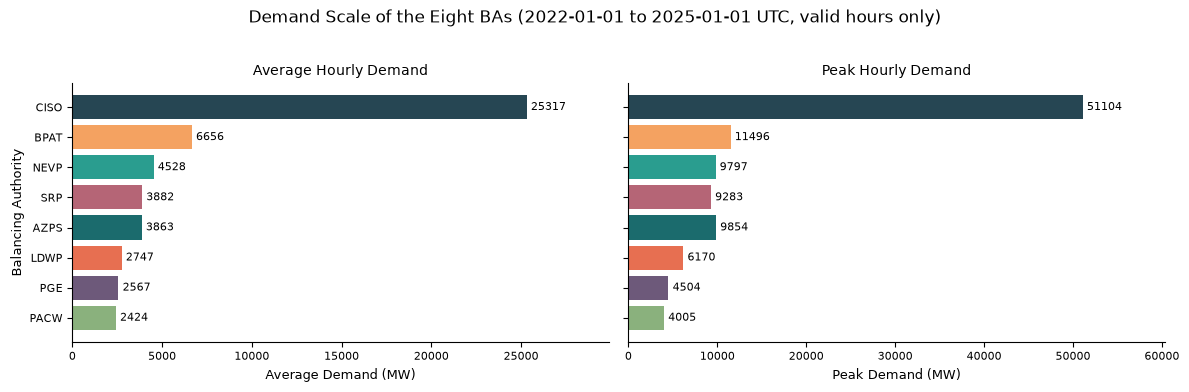

In [11]:
order = sql2["BA_Code"].tolist()
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, col, ttl, xl in [(axs[0], "Average_Demand_MW", "Average Hourly Demand", "Average Demand (MW)"),
                         (axs[1], "Peak_Demand_MW", "Peak Hourly Demand", "Peak Demand (MW)")]:
    vals = sql2.set_index("BA_Code").loc[order, col]
    bars = ax.barh(order[::-1], vals.values[::-1], color=[BA_COLORS[b] for b in order[::-1]])
    ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=8)
    ax.set_xlabel(xl); ax.set_title(ttl); ax.set_xlim(0, vals.max() * 1.18)
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_ylabel("Balancing Authority")
fig.suptitle(f"Demand Scale of the Eight BAs ({PERIOD_START[:10]} to {PERIOD_END[:10]} UTC, valid hours only)", y=1.02)
fig.tight_layout(); savefig(fig, "fig_nb1_fig1_demand_scale")

**Cách đọc Hình 1.** Hai BA có thể có mức trung bình gần nhau nhưng đỉnh khác nhau; khoảng cách giữa đỉnh và trung bình là phần tải lớn nhất cần dự báo tốt khi hệ thống căng. Vì quy mô chênh nhiều lần, các hình tiếp theo dùng *nhu cầu chuẩn hóa theo mean của từng BA* để BA lớn không lấn át BA nhỏ.

### Hình 2 — Hình dạng ngày, tuần (chuẩn hóa) và Hình 3 — nhu cầu theo thời gian

**Hình 2** vẽ cả tám BA trên cùng một panel, đã chia cho mean của chính BA đó (1.0 = mức trung bình), nên so sánh được *hình dạng* mà không bị quy mô chi phối. Trục giờ là giờ địa phương hour-ending. **Hình 3** vẽ demand theo giờ (mờ) và trung bình trượt 7 ngày (đậm) cho từng BA, với đường đứt đánh dấu bắt đầu giai đoạn test.

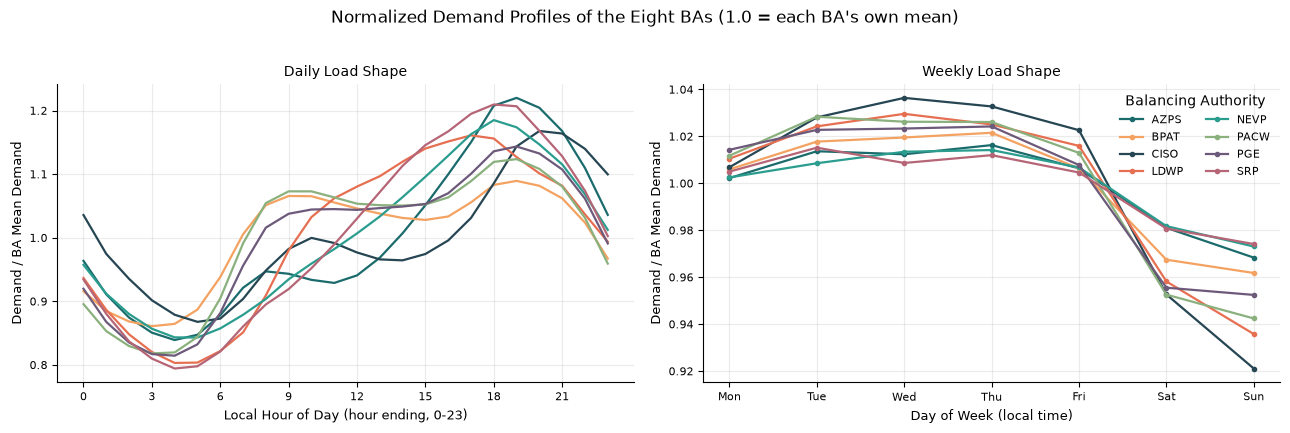

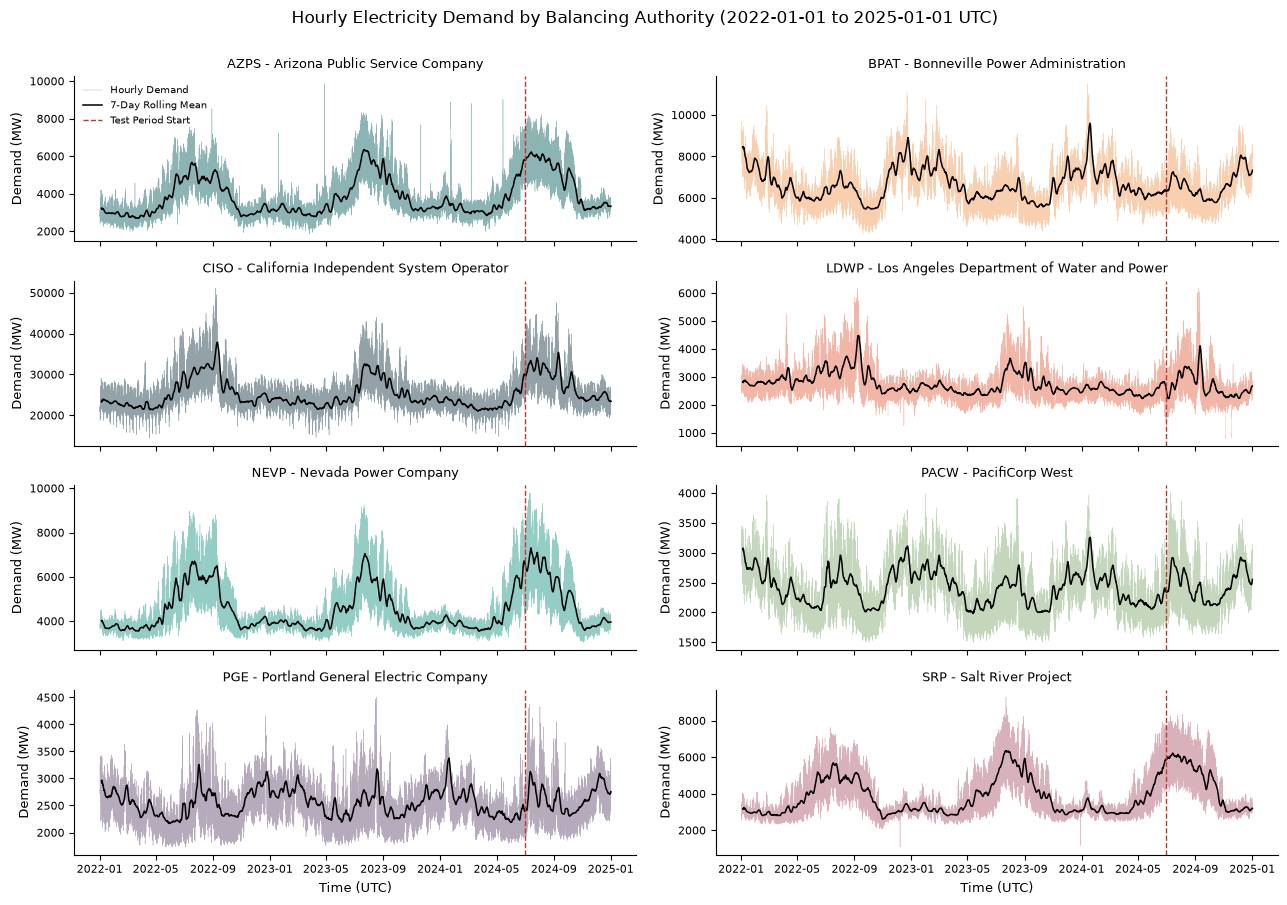

In [12]:
rel_df = clean_df[[UNIT_COL, "hour_local", "dow_local"]].copy()
rel_df["rel"] = clean_df[TARGET_COL] / clean_df.groupby(UNIT_COL)[TARGET_COL].transform("mean")
hr_prof = rel_df.groupby([UNIT_COL, "hour_local"])["rel"].mean().unstack(0).reindex(columns=BA_LIST)
dow_prof = rel_df.groupby([UNIT_COL, "dow_local"])["rel"].mean().unstack(0).reindex(columns=BA_LIST)
hr_prof.round(4).to_csv(f"{REPORT_DIR}/table_hourly_profile_normalized.csv"); dow_prof.round(4).to_csv(f"{REPORT_DIR}/table_weekly_profile_normalized.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ba in BA_LIST:
    axs[0].plot(hr_prof.index, hr_prof[ba], color=BA_COLORS[ba], lw=1.6, label=ba)
    axs[1].plot(dow_prof.index, dow_prof[ba], color=BA_COLORS[ba], lw=1.6, marker="o", ms=3, label=ba)
axs[0].set_xticks(range(0, 24, 3)); axs[0].set_xlabel("Local Hour of Day (hour ending, 0-23)"); axs[0].set_ylabel("Demand / BA Mean Demand")
axs[0].set_title("Daily Load Shape")
axs[1].set_xticks(range(7)); axs[1].set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
axs[1].set_xlabel("Day of Week (local time)"); axs[1].set_ylabel("Demand / BA Mean Demand"); axs[1].set_title("Weekly Load Shape")
axs[1].legend(title="Balancing Authority", ncol=2, frameon=False)
for ax in axs: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
fig.suptitle("Normalized Demand Profiles of the Eight BAs (1.0 = each BA's own mean)", y=1.02)
fig.tight_layout(); savefig(fig, "fig_nb1_fig2_daily_weekly_profiles")

# Hình 3: demand theo thời gian, small multiples
fig, axs = ba_grid(4, 2, figsize=(13, 9), sharex=True)
for ba, ax in axs.items():
    g = grid[grid[UNIT_COL] == ba].set_index(TIME_COL)["demand"]
    ax.plot(g.index, g.values, lw=0.3, color=BA_COLORS[ba], alpha=0.5, label="Hourly Demand")
    ax.plot(g.index, g.rolling(168, min_periods=84).mean(), lw=1.1, color="black", label="7-Day Rolling Mean")
    ax.axvline(pd.Timestamp(TEST_START), color=EVENT_RED, ls="--", lw=1, label="Test Period Start")
    ax.set_title(f"{ba} - {BA_META.loc[ba, 'ba_name']}", fontsize=9); ax.set_ylabel("Demand (MW)")
    ax.spines[["top", "right"]].set_visible(False)
list(axs.values())[0].legend(fontsize=7, frameon=False, loc="upper left")
for ax in list(axs.values())[-2:]: ax.set_xlabel("Time (UTC)")
fig.suptitle(f"Hourly Electricity Demand by Balancing Authority ({PERIOD_START[:10]} to {PERIOD_END[:10]} UTC)", y=1.0)
fig.tight_layout(); savefig(fig, "fig_nb1_fig3_demand_over_time")

**Cách đọc Hình 2 và 3.** Hình 2 cho thấy giờ đỉnh và độ sâu của chu kỳ ngày của từng BA, cùng mức giảm vào cuối tuần (các con số cụ thể nằm trong bảng SQL 2: `Peak_Local_Hour_Ending`, `Weekend_to_Weekday_Ratio`). Nếu các đường lệch nhau về giờ đỉnh, một mô hình dùng chung cho nhiều BA phải học được hình dạng ngày *riêng* của từng BA, từ đặc trưng lịch, mã BA và các lag. Lưu ý các BA ở Arizona (`America/Phoenix`) không đổi giờ mùa hè, còn các BA Thái Bình Dương thì có. Hình 3 cho thấy mức nhu cầu và nhịp mùa của từng BA mà không bị trục y chung chi phối; phần bên phải đường đứt là giai đoạn test của Notebook 2, chỉ gồm nửa cuối năm 2024, tức *thành phần mùa khác* với các năm train. Chỗ đứt đoạn trên đường là các giờ thiếu đã định lượng ở mục 5.

### Hình 4 — Hình dạng mùa (chuẩn hóa theo mean của BA)

Heatmap một panel: mỗi ô là trung bình nhu cầu của *tháng trong năm* (trung bình qua các năm, chỉ tháng đủ dữ liệu) chia cho mean của BA. Hình này thay hai bộ biểu đồ 8-panel của bản gốc (xu hướng tháng và seasonal-by-year), vì Hình 3 đã cho thấy xu hướng theo thời gian. Code cũng kiểm tra chéo tháng đỉnh/thấp với SQL 2.

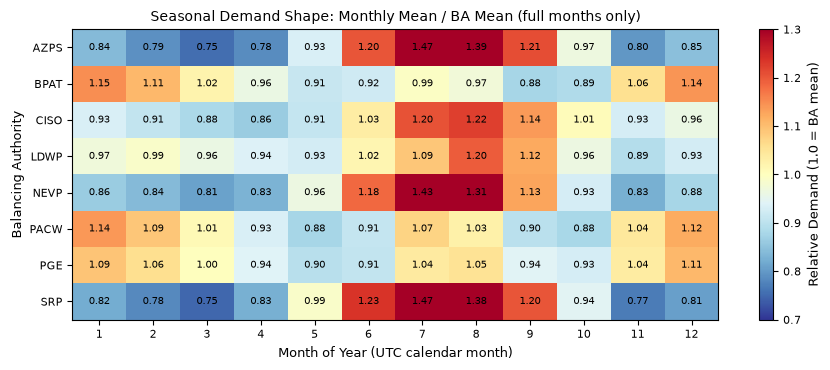

In [13]:
mm = (clean_df.assign(yr=clean_df[TIME_COL].dt.year, mon=clean_df[TIME_COL].dt.month)
      .groupby([UNIT_COL, "yr", "mon"])[TARGET_COL].agg(month_mean="mean", n_valid="count").reset_index())
mm["n_expected"] = [pd.Period(f"{y}-{m:02d}").days_in_month * 24 for y, m in zip(mm["yr"], mm["mon"])]
mm_full = mm[mm["n_valid"] >= MIN_FULL_MONTH_COVERAGE * mm["n_expected"]]
season_mw = mm_full.groupby([UNIT_COL, "mon"])["month_mean"].mean().unstack().reindex(BA_LIST)
season_rel = season_mw.div(clean_df.groupby(UNIT_COL)[TARGET_COL].mean().reindex(BA_LIST), axis=0)
season_rel.round(4).to_csv(f"{REPORT_DIR}/table_seasonal_profile_normalized.csv")

sql2_idx = sql2.set_index("BA_Code")
check("SQL 2 peak and low months equal pandas (full months only)",
      bool((season_mw.idxmax(axis=1).reindex(BA_LIST) == sql2_idx.loc[BA_LIST, "Peak_Month"]).all() and
           (season_mw.idxmin(axis=1).reindex(BA_LIST) == sql2_idx.loc[BA_LIST, "Low_Month"]).all()),
      "peak/low month of the seasonal profile agree between SQL 2 and pandas")

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(season_rel.values, aspect="auto", cmap="RdYlBu_r", vmin=0.7, vmax=1.3)
ax.set_yticks(range(8)); ax.set_yticklabels(BA_LIST); ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
for i in range(season_rel.shape[0]):
    for j in range(season_rel.shape[1]):
        ax.text(j, i, f"{season_rel.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xlabel("Month of Year (UTC calendar month)"); ax.set_ylabel("Balancing Authority")
ax.set_title("Seasonal Demand Shape: Monthly Mean / BA Mean (full months only)")
fig.colorbar(im, ax=ax, label="Relative Demand (1.0 = BA mean)")
fig.tight_layout(); savefig(fig, "fig_nb1_fig4_seasonal_heatmap")

**Cách đọc Hình 4.** Ô đỏ là tháng có nhu cầu cao hơn mức trung bình của BA, ô xanh là thấp hơn. Cột `Peak_Month`, `Low_Month`, `Seasonal_Range_Percent` trong bảng SQL 2 tóm tắt cùng thông tin bằng số. Nếu nhịp mùa mạnh, các đặc trưng lịch (tháng, ngày trong năm) và mức nhu cầu gần đây đều mang thông tin; và vì giai đoạn test chỉ phủ tháng 7 đến tháng 12, Notebook 2 phải báo cáo sai số theo tháng chứ không chỉ một con số trung bình.

## 7. SQL 3 — Demand and CO2 Relationship (RQ1)

**Câu hỏi.** Nhu cầu điện có liên hệ thế nào với cường độ phát thải CO2 trong từng BA?

**Dữ liệu và đơn vị.** Cột `co2_intensity_generated` và `co2_intensity_consumed` đến từ file secondary, ghép với demand của file primary theo `(ba, ts_utc)` (cùng UTC end-of-hour, toàn bộ cửa sổ quan sát ở mục 5). **File không kèm metadata đơn vị**, nên notebook không gán đơn vị cụ thể: hình và bảng ghi "source units", và các phép phân tích chỉ dùng đại lượng không phụ thuộc đơn vị (correlation, nhóm theo phân vị trong từng BA).

**Cách làm.**
* **SQL 3a:** với mỗi BA, correlation Pearson giữa demand và CO2 (generated, consumed), kèm tỷ lệ giờ có CO2 generated bằng 0 và khoảng giá trị. Thêm một cột correlation *sau khi trừ đường cong ngày trung bình* của chính BA đó (độ lệch so với trung bình theo giờ địa phương), để tách phần liên hệ chỉ do cả hai cùng có chu kỳ ngày.
* **SQL 3b:** chia giờ của *từng BA* thành 5 nhóm theo phân vị CO2 generated của chính BA đó, rồi tính nhu cầu tương đối (demand / mean của BA) trong mỗi nhóm. Nhóm theo phân vị *trong BA* tránh lỗi của bản gốc là gộp mọi BA rồi chia decile chung (khi đó nhóm CO2 chủ yếu phản ánh BA nào, không phải mức CO2).

**Cảnh báo.** CO2 intensity được tính từ cơ cấu phát điện, nên đây là liên hệ thống kê, **không phải quan hệ nhân quả**, và phân tích này **không** chứng minh CO2 giúp dự báo. Điều đó chỉ được kiểm tra bằng ablation ở Notebook 2 (RQ3).

In [14]:
SQL3A = """
-- SQL 3a: demand và CO2 intensity TRONG TỪNG BA (không gộp BA, để quy mô và cơ cấu nguồn điện giữa các BA không làm nhiễu)
WITH base AS (
    SELECT ba, hour_local, demand,
           co2_intensity_generated AS co2_gen,
           co2_intensity_consumed  AS co2_con
    FROM clean
    WHERE co2_intensity_generated IS NOT NULL AND co2_intensity_consumed IS NOT NULL),
dev AS (                               -- độ lệch so với đường cong ngày trung bình của chính BA đó
    SELECT ba, demand, co2_gen, co2_con,
           demand  - AVG(demand)  OVER (PARTITION BY ba, hour_local) AS demand_dev,
           co2_gen - AVG(co2_gen) OVER (PARTITION BY ba, hour_local) AS co2_gen_dev
    FROM base)
SELECT m.ba_name                                     AS BA_Name,
       d.ba                                          AS BA_Code,
       COUNT(*)                                      AS Number_of_Matched_Hours,
       ROUND(MIN(d.co2_gen), 3)                      AS CO2_Generated_Min,
       ROUND(MAX(d.co2_gen), 3)                      AS CO2_Generated_Max,
       ROUND(100.0 * AVG(CASE WHEN d.co2_gen = 0 THEN 1.0 ELSE 0.0 END), 1) AS Percent_Zero_CO2_Generated,
       ROUND(corr(d.demand, d.co2_gen), 3)           AS Corr_Demand_CO2_Generated,
       ROUND(corr(d.demand, d.co2_con), 3)           AS Corr_Demand_CO2_Consumed,
       ROUND(corr(d.demand_dev, d.co2_gen_dev), 3)   AS Corr_After_Removing_Hour_Profile
FROM dev d JOIN ba_meta m ON m.ba = d.ba
GROUP BY m.ba_name, d.ba
ORDER BY BA_Code
"""
SQL3B = """
-- SQL 3b: nhu cầu tương đối theo 5 nhóm phân vị CO2 generated, tính TRONG TỪNG BA
-- (nhóm xác định bằng phân vị của chính BA, các giá trị trùng nhau luôn nằm cùng một nhóm, nên nhóm có thể không đều hoặc rỗng khi nhiều giờ CO2 = 0)
WITH base AS (
    SELECT ba, co2_intensity_generated AS co2_gen,
           demand / AVG(demand) OVER (PARTITION BY ba) AS relative_demand
    FROM clean WHERE co2_intensity_generated IS NOT NULL),
thr AS (
    SELECT ba, quantile_cont(co2_gen, [0.2, 0.4, 0.6, 0.8]) AS q FROM base GROUP BY ba),
grp AS (
    SELECT b.ba, b.co2_gen, b.relative_demand,
           CASE WHEN b.co2_gen <= t.q[1] THEN 1
                WHEN b.co2_gen <= t.q[2] THEN 2
                WHEN b.co2_gen <= t.q[3] THEN 3
                WHEN b.co2_gen <= t.q[4] THEN 4
                ELSE 5 END AS CO2_Group
    FROM base b JOIN thr t ON t.ba = b.ba)
SELECT ba AS BA_Code, CO2_Group,
       ROUND(MIN(co2_gen), 3)          AS Min_CO2_Generated,
       ROUND(MAX(co2_gen), 3)          AS Max_CO2_Generated,
       ROUND(AVG(relative_demand), 3)  AS Average_Relative_Demand,
       COUNT(*)                        AS Number_of_Hours
FROM grp GROUP BY ba, CO2_Group
ORDER BY BA_Code, CO2_Group
"""
sql3a = run_sql("sql3a_demand_co2_correlation", SQL3A)
sql3b = run_sql("sql3b_demand_by_co2_group", SQL3B)
sql3a.to_csv(f"{REPORT_DIR}/table_sql3a_demand_co2_correlation.csv", index=False)
sql3b.to_csv(f"{REPORT_DIR}/table_sql3b_demand_by_co2_group.csv", index=False)
display(sql3a.drop(columns=["BA_Name"]))
check("SQL 3 covers eight BAs", sql3a["BA_Code"].nunique() == 8 and sql3b["BA_Code"].nunique() == 8, f"3a: {sql3a['BA_Code'].nunique()} BAs, 3b: {sql3b['BA_Code'].nunique()} BAs")
# kiểm tra chéo correlation với pandas
_cc = clean_df.dropna(subset=EXOG_COLS)
_py = _cc.groupby(UNIT_COL).apply(lambda g: g[TARGET_COL].corr(g["co2_intensity_generated"]), include_groups=False).reindex(sql3a["BA_Code"])
check("SQL 3a correlation equals pandas", bool(np.allclose(_py.fillna(0).to_numpy(), sql3a["Corr_Demand_CO2_Generated"].fillna(0).to_numpy(), atol=0.002)),
      f"max |SQL - pandas| = {np.nanmax(np.abs(_py.to_numpy() - sql3a['Corr_Demand_CO2_Generated'].to_numpy())):.4f}")

,BA_Code,Number_of_Matched_Hours,CO2_Generated_Min,CO2_Generated_Max,Percent_Zero_CO2_Generated,Corr_Demand_CO2_Generated,Corr_Demand_CO2_Consumed,Corr_After_Removing_Hour_Profile
0,AZPS,26300,0.247,1.977,0.0,-0.030,0.238,0.069
1,BPAT,26211,0.008,0.179,0.0,-0.072,-0.037,-0.013
2,CISO,26203,0.015,0.822,0.0,0.207,0.189,0.305
3,LDWP,25460,0.121,1.878,0.0,-0.168,-0.184,0.111
4,NEVP,26302,0.197,1.063,0.0,-0.000,-0.024,0.220
5,PACW,26304,0.008,1.981,0.0,0.037,-0.020,0.066
6,PGE,26304,0.008,0.860,0.0,0.292,0.093,0.384
7,SRP,26187,0.100,0.819,0.0,0.444,0.385,0.547


### Hình 5 — Demand và CO2 trong từng BA (từ SQL 3)

**Panel trái:** correlation trong từng BA, giữa giá trị giờ thô và sau khi trừ đường cong ngày. **Panel phải:** nhu cầu tương đối theo nhóm CO2 (1 = CO2 thấp nhất của BA, 5 = cao nhất). Nhóm trống (do nhiều giờ CO2 bằng nhau) để trống trên đường.

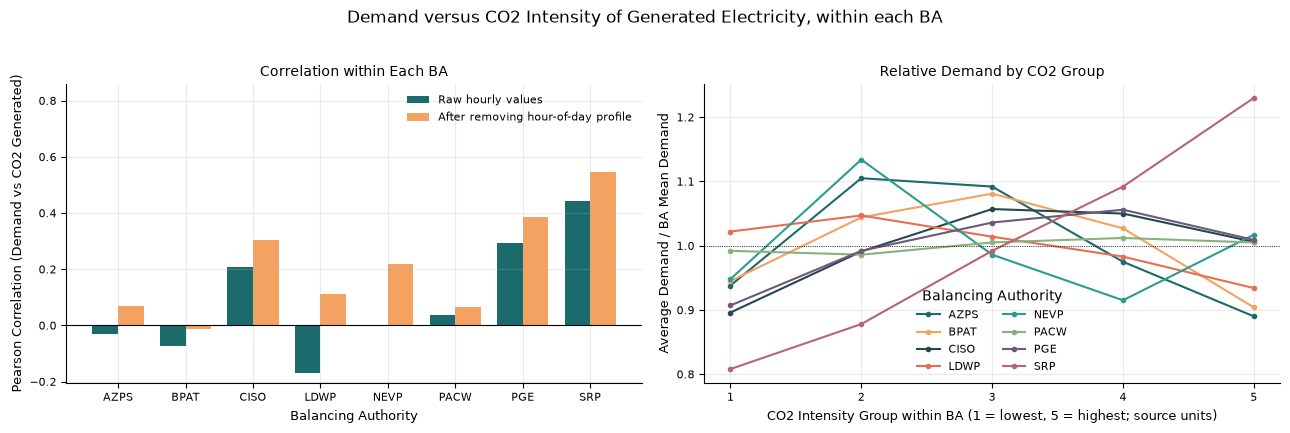

**Kết quả.** Trong từng BA, correlation giữa demand và CO2 generated nằm từ **-0.17** đến **+0.44** (BA thấp nhất: LDWP, cao nhất: SRP). Sau khi trừ đường cong ngày trung bình của từng BA, khoảng này là **-0.01** đến **+0.55**. Tỷ lệ giờ có CO2 generated bằng 0 từ 0.0% đến 0.0% tùy BA (cột `Percent_Zero_CO2_Generated`).

**Nhận xét cho RQ1 (phần CO2).** Hãy so hai cột correlation: nếu liên hệ yếu đi rõ rệt sau khi bỏ chu kỳ ngày, phần lớn liên hệ thô chỉ phản ánh việc nhu cầu và cơ cấu phát điện cùng có nhịp theo giờ. Đây là **liên hệ thống kê trong từng BA**, mức độ khác nhau giữa các BA, và **không phải nhân quả** (CO2 được tính từ cơ cấu phát điện, không điều khiển nhu cầu). Việc CO2 có giúp *dự báo* hay không **chưa được kết luận ở đây**; Notebook 2 sẽ kiểm tra bằng ablation với cùng cách chia dữ liệu và metric.

In [15]:
c1 = sql3a.set_index("BA_Code").loc[BA_LIST]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(8); w = 0.38
axs[0].bar(x - w / 2, c1["Corr_Demand_CO2_Generated"], w, color="#1B6B6D", label="Raw hourly values")
axs[0].bar(x + w / 2, c1["Corr_After_Removing_Hour_Profile"], w, color="#F4A261", label="After removing hour-of-day profile")
axs[0].axhline(0, color="k", lw=0.8); axs[0].set_xticks(x); axs[0].set_xticklabels(BA_LIST)
axs[0].set_ylabel("Pearson Correlation (Demand vs CO2 Generated)"); axs[0].set_xlabel("Balancing Authority")
axs[0].set_title("Correlation within Each BA"); _lo, _hi = axs[0].get_ylim(); axs[0].set_ylim(_lo, _hi + 0.35 * (_hi - _lo)); axs[0].legend(frameon=False, loc="upper right")
piv = sql3b.pivot(index="CO2_Group", columns="BA_Code", values="Average_Relative_Demand").reindex(index=range(1, 6), columns=BA_LIST)
for ba in BA_LIST:
    axs[1].plot(piv.index, piv[ba], marker="o", ms=3, color=BA_COLORS[ba], label=ba)
axs[1].axhline(1, color="k", lw=0.6, ls=":")
axs[1].set_xticks(range(1, 6)); axs[1].set_xlabel("CO2 Intensity Group within BA (1 = lowest, 5 = highest; source units)")
axs[1].set_ylabel("Average Demand / BA Mean Demand"); axs[1].set_title("Relative Demand by CO2 Group"); axs[1].legend(title="Balancing Authority", ncol=2, frameon=False)
for ax in axs: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
fig.suptitle("Demand versus CO2 Intensity of Generated Electricity, within each BA", y=1.02)
fig.tight_layout(); savefig(fig, "fig_nb1_fig5_demand_co2")

lo_c, hi_c = float(c1["Corr_Demand_CO2_Generated"].min()), float(c1["Corr_Demand_CO2_Generated"].max())
lo_d, hi_d = float(c1["Corr_After_Removing_Hour_Profile"].min()), float(c1["Corr_After_Removing_Hour_Profile"].max())
display(Markdown(
    f"**Kết quả.** Trong từng BA, correlation giữa demand và CO2 generated nằm từ **{lo_c:+.2f}** đến **{hi_c:+.2f}** (BA thấp nhất: {c1['Corr_Demand_CO2_Generated'].idxmin()}, cao nhất: {c1['Corr_Demand_CO2_Generated'].idxmax()}). "
    f"Sau khi trừ đường cong ngày trung bình của từng BA, khoảng này là **{lo_d:+.2f}** đến **{hi_d:+.2f}**. "
    f"Tỷ lệ giờ có CO2 generated bằng 0 từ {c1['Percent_Zero_CO2_Generated'].min():.1f}% đến {c1['Percent_Zero_CO2_Generated'].max():.1f}% tùy BA (cột `Percent_Zero_CO2_Generated`).\n\n"
    "**Nhận xét cho RQ1 (phần CO2).** Hãy so hai cột correlation: nếu liên hệ yếu đi rõ rệt sau khi bỏ chu kỳ ngày, phần lớn liên hệ thô chỉ phản ánh việc nhu cầu và cơ cấu phát điện cùng có nhịp theo giờ. "
    "Đây là **liên hệ thống kê trong từng BA**, mức độ khác nhau giữa các BA, và **không phải nhân quả** (CO2 được tính từ cơ cấu phát điện, không điều khiển nhu cầu). "
    "Việc CO2 có giúp *dự báo* hay không **chưa được kết luận ở đây**; Notebook 2 sẽ kiểm tra bằng ablation với cùng cách chia dữ liệu và metric."))

## 8. SQL 4 — Temporal Dependence and Forecasting Signals (RQ1, RQ2)

**Câu hỏi.** Demand cùng giờ ngày hôm trước (lag 24) và cùng giờ tuần trước (lag 168) hữu ích đến mức nào để dự báo?

**Cách làm.** *Self-join theo timestamp*: mỗi giờ `t` được ghép với đúng dòng có timestamp `t − 24 h` (và `t − 168 h`) **của cùng BA**. Cách này không giả định "24 dòng trước" bằng "24 giờ trước"; nếu giờ trước đó thiếu thì dòng không có cặp và bị bỏ khỏi thống kê tương ứng. Chỉ dùng thời điểm *sớm hơn*, không dùng thông tin tương lai.

**Liên hệ với Notebook 2.** Với một dự báo phát hành tại giờ `t` cho giờ đích `T = t + 24`, "cùng giờ hôm trước của giờ đích" là `T − 24 = t` (chính là demand hiện tại: persistence) và "cùng giờ tuần trước của giờ đích" là `T − 168 = t − 144` (weekly naive). Vì vậy `MAE_Lag24_MW` và `MAE_Lag168_MW` dưới đây chính là sai số của hai naive baseline ở Notebook 2 (trên toàn bộ 3 năm, chưa tách train/test).

**Quy ước tính** (với `Matched_Hours_*` là số giờ có cặp): `Mean_Abs_Change_Percent_*` = trung bình của |demand(t) − demand(t−k)| / demand(t−k) × 100.

In [16]:
SQL4 = """
-- SQL 4: demand tại giờ t so với đúng 24 giờ và đúng 168 giờ trước đó (self-join theo BA và timestamp, UTC end-of-hour)
SELECT m.ba_name                                                           AS BA_Name,
       cur.ba                                                              AS BA_Code,
       COUNT(*)                                                            AS Number_of_Valid_Hours,
       COUNT(p24.demand)                                                   AS Matched_Hours_Lag24,
       ROUND(corr(cur.demand, p24.demand), 3)                              AS Corr_Lag24,
       ROUND(AVG(ABS(cur.demand - p24.demand)), 1)                         AS MAE_Lag24_MW,
       ROUND(100.0 * AVG(ABS(cur.demand - p24.demand) / p24.demand), 2)    AS Mean_Abs_Change_Percent_Lag24,
       COUNT(p168.demand)                                                  AS Matched_Hours_Lag168,
       ROUND(corr(cur.demand, p168.demand), 3)                             AS Corr_Lag168,
       ROUND(AVG(ABS(cur.demand - p168.demand)), 1)                        AS MAE_Lag168_MW,
       ROUND(100.0 * AVG(ABS(cur.demand - p168.demand) / p168.demand), 2)  AS Mean_Abs_Change_Percent_Lag168
FROM clean cur
LEFT JOIN clean p24  ON p24.ba  = cur.ba AND p24.ts_utc  = cur.ts_utc - INTERVAL 24 HOUR
LEFT JOIN clean p168 ON p168.ba = cur.ba AND p168.ts_utc = cur.ts_utc - INTERVAL 168 HOUR
JOIN ba_meta m ON m.ba = cur.ba
GROUP BY m.ba_name, cur.ba
ORDER BY BA_Code
"""
sql4 = run_sql("sql4_temporal_dependence", SQL4)
sql4.to_csv(f"{REPORT_DIR}/table_sql4_temporal_dependence.csv", index=False)
display(sql4.drop(columns=["BA_Name"]))
check("SQL 4 covers eight BAs", len(sql4) == 8 and set(sql4["BA_Code"]) == set(BA_LIST), f"{len(sql4)} rows")
# kiểm tra chéo: trên lưới giờ đầy đủ, shift(24) phải cho cùng MAE với self-join theo timestamp
_py24 = grid.groupby(UNIT_COL).apply(lambda g: (g[TARGET_COL] - g[TARGET_COL].shift(24)).abs().mean(), include_groups=False).reindex(sql4["BA_Code"])
check("SQL 4 lag-24 MAE equals pandas shift on the complete grid", bool(np.allclose(_py24.to_numpy(), sql4["MAE_Lag24_MW"].to_numpy(), atol=0.06)),
      f"max |SQL - pandas| = {np.abs(_py24.to_numpy() - sql4['MAE_Lag24_MW'].to_numpy()).max():.3f} MW")

,BA_Code,Number_of_Valid_Hours,Matched_Hours_Lag24,Corr_Lag24,MAE_Lag24_MW,Mean_Abs_Change_Percent_Lag24,Matched_Hours_Lag168,Corr_Lag168,MAE_Lag168_MW,Mean_Abs_Change_Percent_Lag168
0,AZPS,26301,26274,0.968,191.6,4.91,26130,0.903,368.0,9.24
1,BPAT,26304,26280,0.935,265.8,3.96,26136,0.780,474.4,6.86
2,CISO,26251,26198,0.928,1261.8,5.09,26031,0.834,1794.8,6.77
3,LDWP,26186,26069,0.909,172.5,6.22,25900,0.739,276.7,9.63
4,NEVP,26303,26278,0.975,182.5,3.88,26134,0.888,386.1,7.94
5,PACW,26304,26280,0.923,122.2,5.02,26136,0.802,198.5,7.96
6,PGE,26304,26280,0.902,132.1,5.06,26136,0.760,201.9,7.60
7,SRP,26235,26142,0.974,194.7,4.86,25998,0.920,359.3,8.86


### Hình 6 — Phụ thuộc theo thời gian

**Panel trái:** autocorrelation của demand theo độ trễ từ 1 đến 336 giờ (hai tuần) cho tám BA; đường đứng đánh dấu 24 h và 168 h. **Panel phải:** sai khác trung bình |demand(t) − demand(t−k)| theo % của lag 24 và lag 168 (từ SQL 4).

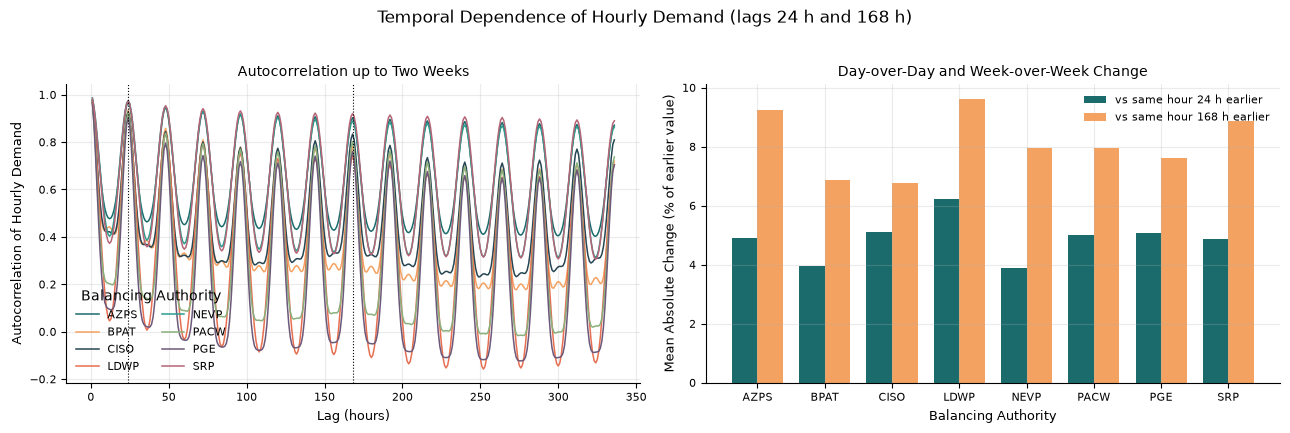

**Kết quả.** Correlation giữa demand và demand 24 giờ trước nằm từ 0.902 đến 0.975; với 168 giờ trước là 0.739 đến 0.920. Sai khác tuyệt đối trung bình so với cùng giờ hôm trước là 3.9%–6.2% giá trị cũ, và so với cùng giờ tuần trước là 6.8%–9.6%. Lag 168 có MAE thấp hơn lag 24 ở **0 trong 8** BA. Mỗi BA có ít nhất 26,069 giờ ghép được cho lag 24 và 25,900 giờ cho lag 168.

**Ý nghĩa.** Demand cùng giờ hôm trước và cùng giờ tuần trước đều là tín hiệu mạnh nhưng không hoàn hảo, nên chúng là baseline tự nhiên (persistence và weekly naive) và là các đặc trưng lag trong Notebook 2. Đây mới chỉ là mô tả tín hiệu lịch sử trên toàn bộ dữ liệu; kết luận về khả năng dự báo chỉ có từ đánh giá train/test ở Notebook 2 (RQ2).

In [17]:
LAG_MAX = 336
dem_series = {ba: g.set_index(TIME_COL)[TARGET_COL] for ba, g in grid.groupby(UNIT_COL)}     # lưới đầy đủ -> shift(k) đúng k giờ
acf = pd.DataFrame({ba: [dem_series[ba].autocorr(lag=k) for k in range(1, LAG_MAX + 1)] for ba in BA_LIST}, index=range(1, LAG_MAX + 1))
acf.round(4).to_csv(f"{REPORT_DIR}/table_autocorrelation_by_lag.csv")

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ba in BA_LIST:
    axs[0].plot(acf.index, acf[ba], color=BA_COLORS[ba], lw=1.1, label=ba)
for k in (24, 168):
    axs[0].axvline(k, color="k", ls=":", lw=0.8)
axs[0].set_xlabel("Lag (hours)"); axs[0].set_ylabel("Autocorrelation of Hourly Demand"); axs[0].set_title("Autocorrelation up to Two Weeks")
axs[0].legend(title="Balancing Authority", ncol=2, frameon=False)
s4 = sql4.set_index("BA_Code").loc[BA_LIST]
x = np.arange(8); w = 0.38
axs[1].bar(x - w / 2, s4["Mean_Abs_Change_Percent_Lag24"], w, color="#1B6B6D", label="vs same hour 24 h earlier")
axs[1].bar(x + w / 2, s4["Mean_Abs_Change_Percent_Lag168"], w, color="#F4A261", label="vs same hour 168 h earlier")
axs[1].set_xticks(x); axs[1].set_xticklabels(BA_LIST); axs[1].set_xlabel("Balancing Authority")
axs[1].set_ylabel("Mean Absolute Change (% of earlier value)"); axs[1].set_title("Day-over-Day and Week-over-Week Change"); axs[1].legend(frameon=False)
for ax in axs: ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25)
fig.suptitle("Temporal Dependence of Hourly Demand (lags 24 h and 168 h)", y=1.02)
fig.tight_layout(); savefig(fig, "fig_nb1_fig6_temporal_dependence")

better168 = int((s4["MAE_Lag168_MW"] < s4["MAE_Lag24_MW"]).sum())
display(Markdown(
    f"**Kết quả.** Correlation giữa demand và demand 24 giờ trước nằm từ {s4.Corr_Lag24.min():.3f} đến {s4.Corr_Lag24.max():.3f}; với 168 giờ trước là {s4.Corr_Lag168.min():.3f} đến {s4.Corr_Lag168.max():.3f}. "
    f"Sai khác tuyệt đối trung bình so với cùng giờ hôm trước là {s4.Mean_Abs_Change_Percent_Lag24.min():.1f}%–{s4.Mean_Abs_Change_Percent_Lag24.max():.1f}% giá trị cũ, và so với cùng giờ tuần trước là {s4.Mean_Abs_Change_Percent_Lag168.min():.1f}%–{s4.Mean_Abs_Change_Percent_Lag168.max():.1f}%. "
    f"Lag 168 có MAE thấp hơn lag 24 ở **{better168} trong 8** BA. Mỗi BA có ít nhất {int(sql4.Matched_Hours_Lag24.min()):,} giờ ghép được cho lag 24 và {int(sql4.Matched_Hours_Lag168.min()):,} giờ cho lag 168.\n\n"
    "**Ý nghĩa.** Demand cùng giờ hôm trước và cùng giờ tuần trước đều là tín hiệu mạnh nhưng không hoàn hảo, nên chúng là baseline tự nhiên (persistence và weekly naive) và là các đặc trưng lag trong Notebook 2. "
    "Đây mới chỉ là mô tả tín hiệu lịch sử trên toàn bộ dữ liệu; kết luận về khả năng dự báo chỉ có từ đánh giá train/test ở Notebook 2 (RQ2)."))

## 9. Giờ nhu cầu cực đoan: định nghĩa ngưỡng và phân bố (phục vụ RQ3)

**Mục tiêu.** Chốt *định nghĩa* giờ cực đoan trước khi Notebook 2 đánh giá cảnh báo, và xem giờ cực đoan xuất hiện khi nào.

**Định nghĩa.** Một giờ là *cực đoan* nếu demand vượt **phân vị 90% của chính BA đó**, ước lượng **chỉ trên giai đoạn train** (trước `TEST_START`) rồi giữ nguyên để áp lên toàn bộ dữ liệu. Nhờ vậy giờ ở giai đoạn test được so với một ngưỡng chưa từng "nhìn thấy" chúng, và không dùng thông tin test để chọn ngưỡng.

Bản gốc còn có bảng sự kiện (gộp các giờ cực đoan liên tiếp), biến thể phân vị 99% và hình quỹ đạo từng sự kiện. Các phần đó đã được bỏ vì không cần cho kết luận của RQ; ngưỡng, tỷ lệ vượt ngưỡng và thời điểm xuất hiện đã đủ làm nền cho RQ3.

,Extreme_Demand_Threshold_MW,Percent_Hours_Above_Threshold_Training,Percent_Hours_Above_Threshold_Test
BA_Code,,,
AZPS,5417.0,10.00,28.48
BPAT,7985.2,10.00,9.15
CISO,30571.0,10.00,25.36
LDWP,3439.6,10.00,13.29
NEVP,6115.3,10.00,24.05
PACW,2996.0,10.00,12.09
PGE,3087.0,9.95,14.62
SRP,5594.0,10.00,25.41


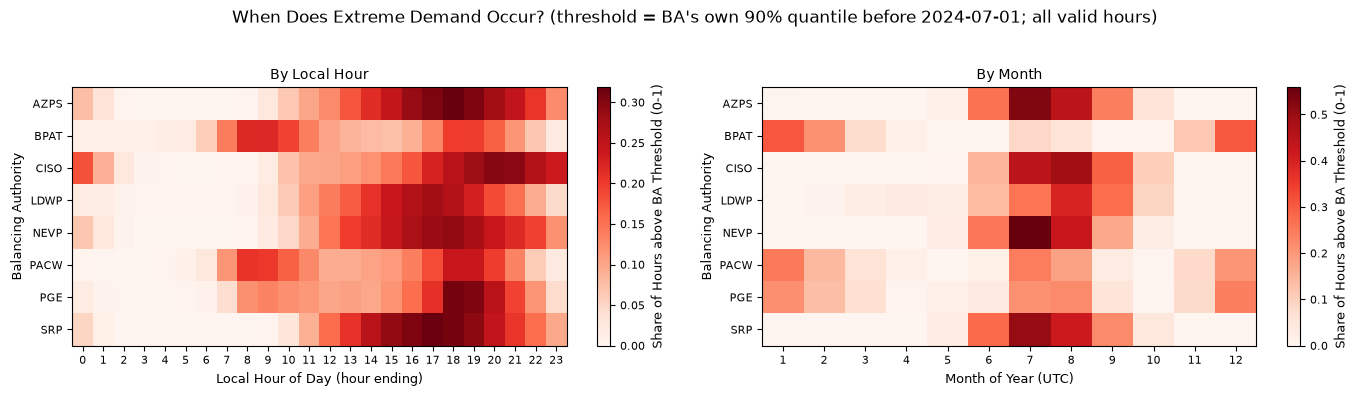

**Kết quả.** Trong giai đoạn train, tỷ lệ giờ vượt ngưỡng nằm quanh 10% như thiết kế (từ 9.9% đến 10.0%; gần 10% là hệ quả của cách xây dựng ngưỡng trên chính các giờ này). Trong giai đoạn **test** tỷ lệ này là 9.2% (BPAT) đến 28.5% (AZPS). Heatmap cho thấy giờ cực đoan tập trung ở những giờ và tháng cụ thể của từng BA (ô sáng nghĩa là cao *so với chính BA đó*, không phải lớn về MW).

**Ý nghĩa cho RQ3.** Ngưỡng cố định từ dữ liệu train gắn nhãn cực đoan cho một tỷ lệ giờ test cao hơn hẳn 10% ở một số BA, vì giai đoạn test là mùa hè đến mùa đông và mức tải có thể đã dịch chuyển so với các năm train. Khi đánh giá cảnh báo ở Notebook 2, tần suất nền (prevalence) của giờ cực đoan trong test phải được báo cáo cùng precision và recall.

In [18]:
train_origin = clean_df[clean_df[TIME_COL] < pd.Timestamp(TEST_START)]
thr_by_q = {q: train_origin.groupby(UNIT_COL)[TARGET_COL].quantile(q).reindex(BA_LIST) for q in EXTREME_QUANTILES}
thr90 = thr_by_q[EVENT_QUANTILE]
clean_df["is_extreme"] = clean_df[TARGET_COL] > clean_df[UNIT_COL].map(thr90)

share = clean_df.groupby([UNIT_COL, "period"])["is_extreme"].mean().unstack().reindex(BA_LIST) * 100
ext_tbl1 = pd.DataFrame({"Extreme_Demand_Threshold_MW": thr90.round(1),
                         "Percent_Hours_Above_Threshold_Training": share["Training period"].round(2),
                         "Percent_Hours_Above_Threshold_Test": share["Test period"].round(2)})
ext_tbl1.index.name = "BA_Code"
ext_tbl1.to_csv(f"{REPORT_DIR}/table_extreme_thresholds_and_shares.csv")
display(ext_tbl1)

by_hour = clean_df.pivot_table(index=UNIT_COL, columns="hour_local", values="is_extreme", aggfunc="mean").reindex(BA_LIST)
by_mon = clean_df.assign(m=clean_df[TIME_COL].dt.month).pivot_table(index=UNIT_COL, columns="m", values="is_extreme", aggfunc="mean").reindex(BA_LIST)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, mat, xl, ttl in [(axs[0], by_hour, "Local Hour of Day (hour ending)", "By Local Hour"),
                         (axs[1], by_mon, "Month of Year (UTC)", "By Month")]:
    im = ax.imshow(mat.values, aspect="auto", cmap="Reds", vmin=0)
    ax.set_yticks(range(8)); ax.set_yticklabels(BA_LIST); ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns, fontsize=8)
    ax.set_xlabel(xl); ax.set_ylabel("Balancing Authority"); ax.set_title(ttl)
    fig.colorbar(im, ax=ax, label="Share of Hours above BA Threshold (0-1)")
fig.suptitle(f"When Does Extreme Demand Occur? (threshold = BA's own {EVENT_QUANTILE:.0%} quantile before {TEST_START}; all valid hours)", y=1.03)
fig.tight_layout(); savefig(fig, "fig_nb1_fig7_extreme_heatmaps")

tr_share, te_share = ext_tbl1["Percent_Hours_Above_Threshold_Training"], ext_tbl1["Percent_Hours_Above_Threshold_Test"]
display(Markdown(
    f"**Kết quả.** Trong giai đoạn train, tỷ lệ giờ vượt ngưỡng nằm quanh {100 * (1 - EVENT_QUANTILE):.0f}% như thiết kế (từ {tr_share.min():.1f}% đến {tr_share.max():.1f}%; gần 10% là hệ quả của cách xây dựng ngưỡng trên chính các giờ này). "
    f"Trong giai đoạn **test** tỷ lệ này là {te_share.min():.1f}% ({te_share.idxmin()}) đến {te_share.max():.1f}% ({te_share.idxmax()}). Heatmap cho thấy giờ cực đoan tập trung ở những giờ và tháng cụ thể của từng BA "
    "(ô sáng nghĩa là cao *so với chính BA đó*, không phải lớn về MW).\n\n"
    "**Ý nghĩa cho RQ3.** Ngưỡng cố định từ dữ liệu train gắn nhãn cực đoan cho một tỷ lệ giờ test cao hơn hẳn 10% ở một số BA, vì giai đoạn test là mùa hè đến mùa đông và mức tải có thể đã dịch chuyển so với các năm train. "
    "Khi đánh giá cảnh báo ở Notebook 2, tần suất nền (prevalence) của giờ cực đoan trong test phải được báo cáo cùng precision và recall."))

## 10. Bảng đặc trưng, target t+24 h và kiểm tra rò rỉ (RQ2, RQ3)

**Câu hỏi.** Notebook 2 nhận được bảng dữ liệu nào, và nó có tránh được look-ahead (dùng thông tin tương lai) và lệch timestamp không?

**Giao thức dự báo (cố định ở đây, dùng lại ở Notebook 2).**

| Hạng mục | Định nghĩa |
|---|---|
| Thời điểm phát hành dự báo | cuối giờ *t* (UTC). Demand đến hết giờ *t* đã biết. |
| Target | `y_h24` = demand tại giờ *t + 24* (MW). **Một target cho mỗi origin**, đánh giá ở mọi origin theo giờ. Đây *không* phải dự báo trọn quỹ đạo 24 giờ của ngày hôm sau, phát hành một lần mỗi ngày. |
| Horizon | 24 giờ (`HORIZONS = [24]`) |
| Đặc trưng có sẵn tại thời điểm phát hành | demand tại *t* (`demand`), lag 1, 2, 3, 24, 48, 144, 168 giờ, trung bình/độ lệch chuẩn trượt 24 giờ kết thúc tại *t*, hiệu 1 giờ, lịch của *t*, và lịch của **giờ đích** (biết trước). |
| Không dùng làm đặc trưng | dự báo EIA day-ahead (`eia_fc_target`, chỉ để so sánh), cột CO2 (thứ cấp, kiểm tra bằng ablation ở Notebook 2), mọi thứ có timestamp sau *t*. |

**Lưu ý về lag.** Với target tại *t + 24*, "cùng giờ hôm qua" chính là *t* (cột `demand`), nên `y_lag24` là cùng giờ **hai ngày** trước giờ đích, và cùng giờ tuần trước của giờ đích là `y_lag144`.

**Cách làm.** Bảng được dựng bằng SQL trên lưới giờ **đầy đủ**. Vì giờ thiếu có mặt dưới dạng dòng demand rỗng, `LAG(k)` và `LEAD(24)` đúng bằng *k* giờ; cửa sổ chứa giờ thiếu cho đặc trưng thiếu, và dòng đó không đủ điều kiện (`eligible = False`).

In [19]:
con.register("grid", grid[[UNIT_COL, TIME_COL, TARGET_COL, "eia_fc"] + EXOG_COLS +
                          ["tgt_hr_local", "tgt_dow_local", "tgt_is_weekend_local", "tgt_mon_local"]])
lag_sql = ",\n       ".join(f"LAG(demand, {k}) OVER w AS y_lag{k}" for k in LAGS)
exog_lag_sql = ",\n       ".join(f"LAG({c}, {SEASON}) OVER w AS {c}_lag_season" for c in EXOG_COLS)
target_sql = ",\n       ".join(f"LEAD(demand, {h}) OVER w AS y_h{h}" for h in HORIZONS)
eia_sql = ",\n       ".join(f"LEAD(eia_fc, {h}) OVER w AS eia_fc_target" for h in HORIZONS[:1])

FEAT_SQL = f"""
CREATE OR REPLACE TABLE feat AS
SELECT ba, ts_utc, demand, eia_fc,
       {", ".join(EXOG_COLS)},
       HOUR(ts_utc) AS hr, ISODOW(ts_utc) - 1 AS dow, MONTH(ts_utc) AS mon, DAYOFYEAR(ts_utc) AS doy,   -- lịch của giờ phát hành (UTC), dow: Thứ Hai = 0
       tgt_hr_local, tgt_dow_local, tgt_is_weekend_local, tgt_mon_local,                                 -- lịch của giờ ĐÍCH (giờ địa phương), biết trước
       {lag_sql},
       CASE WHEN COUNT(demand) OVER w24 = {SEASON} THEN AVG(demand)         OVER w24 END AS y_ma_season,   -- cần đủ 24 giờ
       CASE WHEN COUNT(demand) OVER w24 = {SEASON} THEN STDDEV_SAMP(demand) OVER w24 END AS y_sd_season,
       demand - LAG(demand, 1) OVER w AS y_diff1,
       {exog_lag_sql},
       {target_sql},          -- target: đây là nơi DUY NHẤT dùng giá trị tương lai cho mô hình
       {eia_sql}              -- dự báo EIA cho giờ ĐÍCH (chỉ để so sánh, không phải đặc trưng)
FROM grid
WINDOW w   AS (PARTITION BY ba ORDER BY ts_utc),
       w24 AS (PARTITION BY ba ORDER BY ts_utc ROWS BETWEEN {SEASON - 1} PRECEDING AND CURRENT ROW)
"""
pathlib.Path(f"{SQL_DIR}/features.sql").write_text(FEAT_SQL, encoding="utf-8")
con.execute(FEAT_SQL)
feat = con.execute("SELECT * FROM feat ORDER BY ba, ts_utc").df()
feat[TIME_COL] = pd.to_datetime(feat[TIME_COL]).astype("datetime64[ns]")

PRIMARY_FEATURES = (["demand"] + [f"y_lag{k}" for k in LAGS] + ["y_ma_season", "y_sd_season", "y_diff1", "hr", "dow", "mon", "doy"]
                    + ["tgt_hr_local", "tgt_dow_local", "tgt_is_weekend_local", "tgt_mon_local"])
SECONDARY_FEATURES = EXOG_COLS + [f"{c}_lag_season" for c in EXOG_COLS]
TARGET_NAMES = [f"y_h{h}" for h in HORIZONS]
feat["eligible"] = feat[PRIMARY_FEATURES + TARGET_NAMES].notna().all(axis=1)
feat["target_time_utc"] = feat[TIME_COL] + pd.Timedelta(hours=H)
feat["split_by_target_time"] = np.where(feat["target_time_utc"] < pd.Timestamp(TEST_START), "train", "test")

elig = (feat.groupby(UNIT_COL).agg(Grid_Rows=("eligible", "size"), Eligible_Rows=("eligible", "sum"))
            .assign(Eligible_Percent=lambda d: (100 * d.Eligible_Rows / d.Grid_Rows).round(2)))
elig["Eligible_Train_Rows"] = feat[feat.eligible & (feat.split_by_target_time == "train")].groupby(UNIT_COL).size()
elig["Eligible_Test_Rows"] = feat[feat.eligible & (feat.split_by_target_time == "test")].groupby(UNIT_COL).size()
display(elig)
check("Eight BAs have eligible modeling rows in train and test", bool((elig[["Eligible_Train_Rows", "Eligible_Test_Rows"]].fillna(0) > 0).all().all()),
      f"eligible rows per BA: train {elig['Eligible_Train_Rows'].min():,}-{elig['Eligible_Train_Rows'].max():,}, test {elig['Eligible_Test_Rows'].min():,}-{elig['Eligible_Test_Rows'].max():,}")

,Grid_Rows,Eligible_Rows,Eligible_Percent,Eligible_Train_Rows,Eligible_Test_Rows
ba,,,,,
AZPS,26305,26025,98.94,21601,4424
BPAT,26305,26112,99.27,21687,4425
CISO,26305,25802,98.09,21569,4233
LDWP,26305,25437,96.70,21346,4091
NEVP,26305,26083,99.16,21658,4425
PACW,26305,26112,99.27,21687,4425
PGE,26305,26112,99.27,21687,4425
SRP,26305,25288,96.13,20864,4424


### 10.1 Kiểm tra căn chỉnh timestamp và rò rỉ

Các kiểm tra dưới đây **không dùng lại logic SQL**: chúng tính lại từng đặc trưng và target từ lưới thô bằng *số học timestamp* rồi so sánh.

1. **Target:** `y_h24` tại *t* bằng demand tại *t + 24 h* (ghép theo timestamp, cả tám BA).
2. **Lag:** mỗi `y_lag{k}` bằng demand tại *t − k h*.
3. **Dựng lại từ lịch sử cắt cụt:** với mẫu ngẫu nhiên các dòng đủ điều kiện, dựng lại đặc trưng **chỉ từ dữ liệu đến hết *t***; kết quả phải bằng giá trị SQL (đặc trưng dùng dữ liệu tương lai sẽ không thể tái tạo như vậy).
4. **Quét mã nguồn:** `LEAD` chỉ xuất hiện trong SQL đặc trưng cho target và cho cột so sánh EIA.
5. **Ranh giới chia:** target của dòng train có thời điểm trước `TEST_START`; dòng test từ `TEST_START` trở đi.

Cuối cell là bảng độ phủ của dự báo EIA trên test: Notebook 2 chỉ so sánh với EIA trên các dòng có dự báo này. EIA là một submission riêng của từng BA với thời điểm phát hành riêng, nên so sánh là theo *cùng giờ đích*, không phải cùng tập thông tin.

In [20]:
dem = grid[[UNIT_COL, TIME_COL, TARGET_COL]].rename(columns={TARGET_COL: "d"})

# (1) căn chỉnh target: ghép theo timestamp
t = feat[[UNIT_COL, TIME_COL, "y_h24"]].copy(); t["key"] = t[TIME_COL] + pd.Timedelta(hours=H)
m = t.merge(dem.rename(columns={TIME_COL: "key"}), on=[UNIT_COL, "key"], how="left")
both = m["y_h24"].notna() & m["d"].notna()
check("Target y_h24 = demand at t+24h (timestamp merge, all BAs)", bool(np.allclose(m.loc[both, "y_h24"], m.loc[both, "d"])) and
      bool((m["y_h24"].notna() == m["d"].notna()).all()), f"{int(both.sum()):,} rows compared across {m[UNIT_COL].nunique()} BAs; mismatches = {int((~np.isclose(m.loc[both,'y_h24'], m.loc[both,'d'])).sum())}")

# (2) căn chỉnh các lag
bad = {}
for k in LAGS:
    t = feat[[UNIT_COL, TIME_COL, f"y_lag{k}"]].copy(); t["key"] = t[TIME_COL] - pd.Timedelta(hours=k)
    mm = t.merge(dem.rename(columns={TIME_COL: "key"}), on=[UNIT_COL, "key"], how="left")
    ok = mm[f"y_lag{k}"].notna() | mm["d"].notna()
    bad[k] = int((~np.isclose(mm.loc[ok, f"y_lag{k}"].fillna(-1), mm.loc[ok, "d"].fillna(-1))).sum())
check("Lag features y_lag{k} = demand at t-k (timestamp merge, all BAs)", sum(bad.values()) == 0, f"mismatches by lag: {bad}")

# (3) dựng lại đặc trưng từ lịch sử cắt cụt
ser = {ba: g.set_index(TIME_COL)[TARGET_COL] for ba, g in grid.groupby(UNIT_COL)}
sample = feat[feat["eligible"]].sample(400, random_state=SEED)
n_bad = 0
for _, r in sample.iterrows():
    hist = ser[r[UNIT_COL]].loc[: r[TIME_COL]]             # thông tin có tại thời điểm phát hành: không có gì sau t
    exp = {f"y_lag{k}": hist.loc[r[TIME_COL] - pd.Timedelta(hours=k)] for k in LAGS}
    last24 = hist.iloc[-SEASON:]
    exp.update(y_ma_season=last24.mean(), y_sd_season=last24.std(ddof=1), y_diff1=hist.iloc[-1] - hist.iloc[-2])
    n_bad += int(not all(np.isclose(exp[k], r[k]) for k in exp))
check("Features reproducible from history up to t only (400 random eligible rows)", n_bad == 0, f"{n_bad} irreproducible rows out of {len(sample)}")

# (4) quét mã nguồn: LEAD chỉ dùng cho target và cột so sánh EIA
lead_lines = [l for l in FEAT_SQL.splitlines() if "LEAD(" in l]
check("LEAD() used only for target and EIA comparator", len(lead_lines) == len(HORIZONS) + 1 and all(("y_h" in l or "eia_fc_target" in l) for l in lead_lines),
      f"{len(lead_lines)} LEAD expressions: " + " | ".join(l.strip()[:45] for l in lead_lines))

# (5) ranh giới chia theo thời điểm của target
tr, te = feat[feat.eligible & (feat.split_by_target_time == "train")], feat[feat.eligible & (feat.split_by_target_time == "test")]
check("Train targets precede test targets (boundary on target time)", tr["target_time_utc"].max() < te["target_time_utc"].min() and te["target_time_utc"].min() >= pd.Timestamp(TEST_START),
      f"last train target {tr['target_time_utc'].max()} < first test target {te['target_time_utc'].min()} (TEST_START {TEST_START})",
      "Features of early test rows use history before TEST_START; this is allowed (available at issue time). Training rows never use test targets.")
check("Statistics for extreme thresholds from training period only", True, "SQL 3 and section 9 estimate quantiles on ts_utc < TEST_START",
      "Notebook 2 recomputes thresholds from training TARGETS (target_time < TEST_START).")

In [21]:
te_all = feat[(feat["split_by_target_time"] == "test") & feat["eligible"]]
eia_cov = (te_all.groupby(UNIT_COL).agg(Eligible_Test_Rows=("eligible", "size"),
                                         EIA_Forecast_Available=("eia_fc_target", lambda s: int((s.notna() & (s > 0)).sum())))
           .assign(EIA_Coverage_Percent=lambda d: (100 * d.EIA_Forecast_Available / d.Eligible_Test_Rows).round(1)))
eia_cov.to_csv(f"{REPORT_DIR}/table_eia_forecast_coverage_test.csv")
display(eia_cov)

,Eligible_Test_Rows,EIA_Forecast_Available,EIA_Coverage_Percent
ba,,,
AZPS,4424,4424,100.0
BPAT,4425,4425,100.0
CISO,4233,4233,100.0
LDWP,4091,4091,100.0
NEVP,4425,4425,100.0
PACW,4425,4425,100.0
PGE,4425,4425,100.0
SRP,4424,4424,100.0


**Nhận xét.** Nếu cả năm phép kiểm tra đều PASS, target `y_h24` và các lag đã đúng với timestamp, đặc trưng tái tạo được từ lịch sử đến hết *t*, và ranh giới train/test đặt theo *thời điểm của target* (bản gốc chia theo thời điểm phát hành, khiến target của 24 origin cuối của train rơi vào giai đoạn test). Đặc trưng của các dòng test sớm dùng lịch sử trước `TEST_START`, điều này hợp lệ vì chúng có sẵn tại thời điểm phát hành. Bảng độ phủ EIA cho biết phần dòng test có dự báo EIA để so sánh.

## 11. Xuất dữ liệu cho Notebook 2 và tóm tắt

**Mục tiêu.** Ghi bảng đặc trưng và một *manifest* (BA, quy ước thời gian, target, vai trò từng cột, ranh giới train/test, checksum). Notebook 2 đọc manifest, kiểm tra lại checksum và danh sách BA, và không tự chọn BA.

In [22]:
# 11.1 Lưu bảng đặc trưng (ưu tiên parquet, nếu thiếu pyarrow thì dùng CSV và có thông báo rõ ràng)
handoff_cols = [UNIT_COL, TIME_COL, "target_time_utc", "split_by_target_time", "eligible", TARGET_COL, *PRIMARY_FEATURES[1:], *TARGET_NAMES,
                "eia_fc", "eia_fc_target", *SECONDARY_FEATURES]
out = feat[handoff_cols].copy()
try:
    HANDOFF_PATH, HANDOFF_FORMAT = f"{PROC_DIR}/feat_8ba.parquet", "parquet"
    out.to_parquet(HANDOFF_PATH, index=False)
except ImportError:
    HANDOFF_PATH, HANDOFF_FORMAT = f"{PROC_DIR}/feat_8ba.csv", "csv"
    out.to_csv(HANDOFF_PATH, index=False)
    print("CẢNH BÁO: chưa cài pyarrow nên ghi CSV thay cho parquet (Notebook 2 sẽ parse lại kiểu dữ liệu).")
md5 = hashlib.md5(open(HANDOFF_PATH, "rb").read()).hexdigest()

columns_doc = {
    UNIT_COL: "BA code (one of the eight)", TIME_COL: "forecast ISSUE hour, UTC, end-of-hour timestamp",
    "target_time_utc": "ts_utc + 24 h; the hour being forecast", "split_by_target_time": "'train' if target_time_utc < TEST_START else 'test'",
    "eligible": "all PRIMARY_FEATURES and the target are non-missing (full history, no gap)", "demand": "demand at the issue hour t, MW (also feature 'y_lag0')",
    "y_h24": "TARGET: demand at t+24 h, MW", "eia_fc": "EIA day-ahead forecast for hour t, MW", "eia_fc_target": "EIA day-ahead forecast for hour t+24, MW (comparator only)",
    "y_lag{k}": "demand at t-k hours, MW (k in %s)" % LAGS, "y_ma_season / y_sd_season": "mean / std of demand over the 24 hours ending at t (MW)",
    "y_diff1": "demand(t) - demand(t-1), MW", "hr, dow, mon, doy": "UTC hour, day of week (Mon=0), month, day of year of hour t",
    "tgt_hr_local, tgt_dow_local, tgt_is_weekend_local, tgt_mon_local": "local wall-clock calendar of the target hour (known at issue time)",
    "co2_*": "CO2 intensity from the secondary file (units as in source); secondary, not a primary predictor",
}
manifest = {
    "group": GROUP, "stage": "notebook1_handoff", "handoff_file": HANDOFF_PATH, "handoff_format": HANDOFF_FORMAT, "md5": md5,
    "ba_list": BA_LIST, "n_ba": len(BA_LIST), "ba_names": BA_META.loc[BA_LIST, "ba_name"].to_dict(), "ba_timezones": BA_META.loc[BA_LIST, "tz"].to_dict(),
    "unit_col": UNIT_COL, "time_col": TIME_COL, "target_col": TARGET_COL, "freq": FREQ, "season": SEASON, "horizons": HORIZONS,
    "test_start": TEST_START, "event_quantile": EVENT_QUANTILE, "extreme_quantiles": EXTREME_QUANTILES,
    "grid_start_utc": str(GRID_START), "grid_end_utc": str(GRID_END), "n_rows": int(len(out)), "n_eligible_rows": int(out["eligible"].sum()),
    "time_convention": "UTC end-of-hour timestamps; demand in MW (hourly average); local time used only for derived calendar features",
    "protocol": {"issue_time": "end of hour t (UTC)", "target": "demand at t+24h", "targets_per_origin": 1,
                 "split": "train = target_time < TEST_START; test = target_time >= TEST_START (no overlap of train targets with the test period)"},
    "primary_features": PRIMARY_FEATURES, "secondary_features": SECONDARY_FEATURES, "target_columns": TARGET_NAMES,
    "comparator_columns": ["eia_fc_target"], "columns": columns_doc, "dtypes": {c: str(t) for c, t in out.dtypes.items()},
    "cleaning": {"quantile_clipping": "removed (original clipped at per-BA 0.1/99.9 % over the whole period)", "interpolation": "none; gaps remain missing",
                 "implausible_rule": f"demand < {IMPLAUSIBLE_LOW}x or > {IMPLAUSIBLE_HIGH}x per-BA TRAIN median set to missing"},
    "extreme_thresholds_train_mw": {str(q): thr_by_q[q].round(1).to_dict() for q in EXTREME_QUANTILES},
}
json.dump(manifest, open(f"{PROC_DIR}/manifest_8ba.json", "w"), indent=2, default=str)
cleaning_log_df.to_csv(f"{REPORT_DIR}/table_cleaning_log.csv", index=False)
print(f"Đã lưu {HANDOFF_PATH} ({len(out):,} dòng, {out.shape[1]} cột, {int(out['eligible'].sum()):,} dòng đủ điều kiện) và {PROC_DIR}/manifest_8ba.json (md5 {md5[:8]}...)")

schema = pd.DataFrame({"Column": out.columns, "Type": [str(t) for t in out.dtypes],
                       "Role": ["key" if c in (UNIT_COL, TIME_COL) else "target" if c in TARGET_NAMES else "comparator" if c.startswith("eia") else
                                "secondary" if c in SECONDARY_FEATURES else "primary feature" if c in PRIMARY_FEATURES else "metadata" for c in out.columns]})
display(schema)

Đã lưu data/processed/feat_8ba.parquet (210,440 dòng, 31 cột, 206,971 dòng đủ điều kiện) và data/processed/manifest_8ba.json (md5 bef1e94a...)


,Column,Type,Role
0,ba,object,key
1,ts_utc,datetime64[ns],key
2,target_time_utc,datetime64[ns],metadata
3,split_by_target_time,object,metadata
4,eligible,bool,metadata
5,demand,float64,primary feature
6,y_lag1,float64,primary feature
7,y_lag2,float64,primary feature
8,y_lag3,float64,primary feature
9,y_lag24,float64,primary feature


In [23]:
# 11.2 Kiểm tra cuối cùng trên dữ liệu chuyển giao
chk_out = out.sort_values([UNIT_COL, TIME_COL])
hourly_ok = bool(chk_out.groupby(UNIT_COL)[TIME_COL].apply(lambda s: bool((s.diff().dropna() == pd.Timedelta(hours=1)).all())).all())
check("Handoff table: exactly eight BAs, unique keys, regular hourly steps",
      out[UNIT_COL].nunique() == 8 and not out.duplicated([UNIT_COL, TIME_COL]).any() and hourly_ok,
      f"{out[UNIT_COL].nunique()} BAs, duplicate keys = {int(out.duplicated([UNIT_COL, TIME_COL]).sum())}, hourly spacing ok = {hourly_ok}")
check("Handoff artifact written with checksum", os.path.exists(HANDOFF_PATH) and len(md5) == 32, f"{HANDOFF_PATH}; md5 {md5}")
check("Manifest holds exactly eight BAs", manifest["n_ba"] == 8 and manifest["ba_list"] == BA_LIST, f"{manifest['ba_list']}")
check("Forecast horizon and test boundary preserved", manifest["horizons"] == [24] and manifest["test_start"] == "2024-07-01", f"horizons={manifest['horizons']}, test_start={manifest['test_start']}")
val = pd.DataFrame(VALIDATION)
val.to_csv(f"{REPORT_DIR}/validation_notebook1.csv", index=False)
display(val)

,Validation_Check,Status,Evidence,Remaining_Issue
0,BA count (secondary source),PASS,"8 BAs in secondary file: ['AZPS', 'BPAT', 'CIS...",
1,BA list equals EXPECTED_8BA,PASS,"data: ['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP',...","Nếu chủ động đổi phạm vi, hãy sửa EXPECTED_8BA..."
2,All eight BAs present in primary source,PASS,primary file holds 63 BAs; missing from primar...,
3,SQL 1 covers exactly eight BAs,PASS,"8 rows: ['AZPS', 'BPAT', 'CISO', 'LDWP', 'NEVP...",
4,Primary and secondary demand agree on comparab...,PASS,"max MAE = 0.000 MW, min correlation = 1.00000,...","Nếu không nhất quán, cần chọn nguồn authoritat..."
5,Exactly eight BAs in analysis dataset,PASS,8 BAs in grid,
6,Timestamps ordered and unique within BA,PASS,"monotonic=True, duplicate keys after cleaning=0",
7,Regular hourly grid,PASS,"26,305 hourly steps per BA, all eight BAs",
8,Time coverage documented,PASS,2022-01-01 08:00:00 to 2025-01-01 08:00:00 (UT...,Longest gap: 49 h; missing share per BA: 0.004...
9,SQL 2 returns eight BAs,PASS,"8 rows: ['CISO', 'BPAT', 'NEVP', 'SRP', 'AZPS'...",


### Tóm tắt phát hiện chính của Notebook 1

Đoạn văn dưới đây được **sinh từ kết quả vừa tính**, không gõ sẵn con số.

In [24]:
n_pass, n_warn = int((val.Status == "PASS").sum()), int((val.Status == "WARN").sum())
s2, s3, s4s = sql2.set_index("BA_Code"), sql3a.set_index("BA_Code"), sql4.set_index("BA_Code")
display(Markdown(
    f"**Phạm vi.** {len(BA_LIST)} BA ({', '.join(BA_LIST)}), lưới giờ UTC từ {GRID_START} đến {GRID_END}; giai đoạn test bắt đầu từ target {TEST_START}. "
    f"Bảng chuyển giao có {len(out):,} dòng, trong đó {int(out['eligible'].sum()):,} dòng đủ điều kiện mô hình hóa.\n\n"
    f"**RQ1 — nhất quán giữa hai nguồn.** " + ("Với các giờ ghép được, hai nguồn khớp demand trong dung sai 1 MW; " if consistent else "Hai nguồn có chênh lệch demand ở ít nhất một BA (xem SQL 1); ")
    + f"MAE lớn nhất giữa hai nguồn là {worst_mae:.3f} MW; có {only_p:,} bản ghi chỉ ở primary và {only_s:,} chỉ ở secondary.\n\n"
    f"**RQ1 — cấu trúc của demand.** Quy mô trung bình khác nhau {sql2.Average_Demand_MW.max() / sql2.Average_Demand_MW.min():.1f} lần giữa BA lớn nhất và nhỏ nhất; "
    f"biên độ mùa từ {sql2.Seasonal_Range_Percent.min():.1f}% đến {sql2.Seasonal_Range_Percent.max():.1f}% so với mean; tỷ số cuối tuần/ngày thường từ {sql2.Weekend_to_Weekday_Ratio.min():.3f} đến {sql2.Weekend_to_Weekday_Ratio.max():.3f}. "
    f"Liên hệ demand–CO2 trong từng BA nằm từ {lo_c:+.2f} đến {hi_c:+.2f} (còn {lo_d:+.2f} đến {hi_d:+.2f} sau khi trừ chu kỳ ngày); đây là liên hệ thống kê, **không** phải bằng chứng nhân quả hay bằng chứng CO2 giúp dự báo.\n\n"
    f"**Tín hiệu cho dự báo (RQ1, RQ2).** Correlation với 24 giờ trước nằm từ {s4s.Corr_Lag24.min():.3f} đến {s4s.Corr_Lag24.max():.3f}, với 168 giờ trước từ {s4s.Corr_Lag168.min():.3f} đến {s4s.Corr_Lag168.max():.3f}.\n\n"
    f"**Cho RQ3.** Ngưỡng giờ cực đoan (phân vị {EVENT_QUANTILE:.0%} giai đoạn train) vượt {te_share.min():.1f}%–{te_share.max():.1f}% giờ của giai đoạn test, cao hơn tỷ lệ danh nghĩa {100 * (1 - EVENT_QUANTILE):.0f}%.\n\n"
    f"**Kiểm tra.** {n_pass} phép kiểm tra PASS, {n_warn} cảnh báo (WARN), 0 FAIL (nếu có FAIL notebook đã dừng).\n\n"
    "**Chưa được thiết lập ở notebook này.** Khả năng dự báo của bất kỳ mô hình nào (RQ2), độ tin cậy của khoảng dự báo, hiệu quả cảnh báo giờ cực đoan và tác dụng của CO2 (RQ3). "
    "Hạn chế mang sang Notebook 2: giai đoạn test chỉ gồm nửa cuối năm 2024, không có dữ liệu thời tiết, và vị trí BA trên bản đồ chỉ là xấp xỉ."))

**Phạm vi.** 8 BA (AZPS, BPAT, CISO, LDWP, NEVP, PACW, PGE, SRP), lưới giờ UTC từ 2022-01-01 08:00:00 đến 2025-01-01 08:00:00; giai đoạn test bắt đầu từ target 2024-07-01. Bảng chuyển giao có 210,440 dòng, trong đó 206,971 dòng đủ điều kiện mô hình hóa.

**RQ1 — nhất quán giữa hai nguồn.** Với các giờ ghép được, hai nguồn khớp demand trong dung sai 1 MW; MAE lớn nhất giữa hai nguồn là 0.000 MW; có 0 bản ghi chỉ ở primary và 24 chỉ ở secondary.

**RQ1 — cấu trúc của demand.** Quy mô trung bình khác nhau 10.4 lần giữa BA lớn nhất và nhỏ nhất; biên độ mùa từ 21.0% đến 72.4% so với mean; tỷ số cuối tuần/ngày thường từ 0.914 đến 0.969. Liên hệ demand–CO2 trong từng BA nằm từ -0.17 đến +0.44 (còn -0.01 đến +0.55 sau khi trừ chu kỳ ngày); đây là liên hệ thống kê, **không** phải bằng chứng nhân quả hay bằng chứng CO2 giúp dự báo.

**Tín hiệu cho dự báo (RQ1, RQ2).** Correlation với 24 giờ trước nằm từ 0.902 đến 0.975, với 168 giờ trước từ 0.739 đến 0.920.

**Cho RQ3.** Ngưỡng giờ cực đoan (phân vị 90% giai đoạn train) vượt 9.2%–28.5% giờ của giai đoạn test, cao hơn tỷ lệ danh nghĩa 10%.

**Kiểm tra.** 27 phép kiểm tra PASS, 0 cảnh báo (WARN), 0 FAIL (nếu có FAIL notebook đã dừng).

**Chưa được thiết lập ở notebook này.** Khả năng dự báo của bất kỳ mô hình nào (RQ2), độ tin cậy của khoảng dự báo, hiệu quả cảnh báo giờ cực đoan và tác dụng của CO2 (RQ3). Hạn chế mang sang Notebook 2: giai đoạn test chỉ gồm nửa cuối năm 2024, không có dữ liệu thời tiết, và vị trí BA trên bản đồ chỉ là xấp xỉ.